In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw")

sales = pd.read_csv(DATA_DIR / "sales_pipeline.csv")
accounts = pd.read_csv(DATA_DIR / "accounts.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
sales_teams = pd.read_csv(DATA_DIR / "sales_teams.csv")
dictionary = pd.read_csv(DATA_DIR / "data_dictionary.csv")

print("Sales:", sales.shape)
print("Accounts:", accounts.shape)
print("Products:", products.shape)
print("Sales teams:", sales_teams.shape)
print("Data dictionary:", dictionary.shape)

Sales: (8800, 8)
Accounts: (85, 7)
Products: (7, 3)
Sales teams: (35, 3)
Data dictionary: (21, 3)


In [4]:
# Inspect the structure of each table
datasets = {
    "Sales": sales,
    "Accounts": accounts,
    "Products": products,
    "Sales Teams": sales_teams,
    "Data Dictionary": dictionary
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name.upper()} — COLUMN NAMES")
    print("=" * 60)
    print(df.columns.tolist())


SALES — COLUMN NAMES
['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage', 'engage_date', 'close_date', 'close_value']

ACCOUNTS — COLUMN NAMES
['account', 'sector', 'year_established', 'revenue', 'employees', 'office_location', 'subsidiary_of']

PRODUCTS — COLUMN NAMES
['product', 'series', 'sales_price']

SALES TEAMS — COLUMN NAMES
['sales_agent', 'manager', 'regional_office']

DATA DICTIONARY — COLUMN NAMES
['Table', 'Field', 'Description']


In [5]:
# View the first five rows of each table
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    display(df.head())

# Inspect column types and non-null counts
print("\n--- SALES DATA TYPES AND COMPLETENESS ---")
sales.info()


--- SALES ---


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0



--- ACCOUNTS ---


,account,sector,year_established,revenue,employees,office_location,subsidiary_of
0,Acme Corporation,technolgy,1996,1100.04,2822,United States,NaN
1,Betasoloin,medical,1999,251.41,495,United States,NaN
2,Betatech,medical,1986,647.18,1185,Kenya,NaN
3,Bioholding,medical,2012,587.34,1356,Philipines,NaN
4,Bioplex,medical,1991,326.82,1016,United States,NaN



--- PRODUCTS ---


,product,series,sales_price
0,GTX Basic,GTX,550
1,GTX Pro,GTX,4821
2,MG Special,MG,55
3,MG Advanced,MG,3393
4,GTX Plus Pro,GTX,5482



--- SALES TEAMS ---


,sales_agent,manager,regional_office
0,Anna Snelling,Dustin Brinkmann,Central
1,Cecily Lampkin,Dustin Brinkmann,Central
2,Versie Hillebrand,Dustin Brinkmann,Central
3,Lajuana Vencill,Dustin Brinkmann,Central
4,Moses Frase,Dustin Brinkmann,Central



--- DATA DICTIONARY ---


,Table,Field,Description
0,accounts,account,Company name
1,accounts,sector,Industry
2,accounts,year_established,Year Established
3,accounts,revenue,Annual revenue (in millions of USD)
4,accounts,employees,Number of employees



--- SALES DATA TYPES AND COMPLETENESS ---
<class 'pandas.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   opportunity_id  8800 non-null   str    
 1   sales_agent     8800 non-null   str    
 2   product         8800 non-null   str    
 3   account         7375 non-null   str    
 4   deal_stage      8800 non-null   str    
 5   engage_date     8300 non-null   str    
 6   close_date      6711 non-null   str    
 7   close_value     6711 non-null   float64
dtypes: float64(1), str(7)
memory usage: 550.1 KB


In [6]:
# STEP 5.2: Quantify missing values

missing_audit = pd.DataFrame({
    "Missing_Count": sales.isnull().sum(),
    "Missing_Percentage": (
        sales.isnull().mean() * 100
    ).round(2),
    "Unique_Values": sales.nunique()
})

missing_audit = missing_audit.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_audit)

,Missing_Count,Missing_Percentage,Unique_Values
close_date,2089,23.74,306
close_value,2089,23.74,2051
account,1425,16.19,85
engage_date,500,5.68,421
opportunity_id,0,0.00,8800
sales_agent,0,0.00,30
product,0,0.00,7
deal_stage,0,0.00,4


In [7]:
# STEP 5.3: Compare missingness across deal stages

stage_audit = sales.groupby(
    "deal_stage",
    dropna=False
).agg(
    Total_Records=("opportunity_id", "size"),
    Missing_Account=("account", lambda x: x.isnull().sum()),
    Missing_Close_Date=("close_date", lambda x: x.isnull().sum()),
    Missing_Close_Value=("close_value", lambda x: x.isnull().sum()),
    Average_Close_Value=("close_value", "mean")
).reset_index()

display(stage_audit)

,deal_stage,Total_Records,Missing_Account,Missing_Close_Date,Missing_Close_Value,Average_Close_Value
0,Engaging,1589,1088,1589,1589,NaN
1,Lost,2473,0,0,0,0.000000
2,Prospecting,500,337,500,500,NaN
3,Won,4238,0,0,0,2360.909391


In [8]:
# STEP 5.4: Check record uniqueness

print("Total rows:", len(sales))
print("Unique opportunity IDs:", sales["opportunity_id"].nunique())
print(
    "Duplicate opportunity IDs:",
    sales["opportunity_id"].duplicated().sum()
)

print("\nDeal stage distribution:")
display(
    sales["deal_stage"]
    .value_counts(dropna=False)
    .rename_axis("Deal_Stage")
    .reset_index(name="Record_Count")
)

Total rows: 8800
Unique opportunity IDs: 8800
Duplicate opportunity IDs: 0

Deal stage distribution:


,Deal_Stage,Record_Count
0,Won,4238
1,Lost,2473
2,Engaging,1589
3,Prospecting,500


In [9]:
# STEP 6.1: Convert date columns into datetime format

sales["engage_date"] = pd.to_datetime(
    sales["engage_date"],
    errors="coerce"
)

sales["close_date"] = pd.to_datetime(
    sales["close_date"],
    errors="coerce"
)

# Check the date ranges
print("Earliest engagement date:",
      sales["engage_date"].min())

print("Latest engagement date:",
      sales["engage_date"].max())

print("Earliest close date:",
      sales["close_date"].min())

print("Latest close date:",
      sales["close_date"].max())

# Check for invalid or missing dates
print("\nMissing engagement dates:",
      sales["engage_date"].isna().sum())

print("Missing close dates:",
      sales["close_date"].isna().sum())

Earliest engagement date: 2016-10-20 00:00:00
Latest engagement date: 2017-12-27 00:00:00
Earliest close date: 2017-03-01 00:00:00
Latest close date: 2017-12-31 00:00:00

Missing engagement dates: 500
Missing close dates: 2089


In [10]:
# STEP 6.2: Validate the relationship between dates

valid_dates = sales.dropna(
    subset=["engage_date", "close_date"]
).copy()

valid_dates["sales_cycle_days"] = (
    valid_dates["close_date"]
    - valid_dates["engage_date"]
).dt.days

print("Records with both dates:",
      len(valid_dates))

print("Negative sales cycles:",
      (valid_dates["sales_cycle_days"] < 0).sum())

print("\nSales cycle summary:")
display(
    valid_dates["sales_cycle_days"].describe()
)

Records with both dates: 6711
Negative sales cycles: 0

Sales cycle summary:


count    6711.000000
mean       47.985397
std        41.057665
min         1.000000
25%         8.000000
50%        45.000000
75%        85.000000
max       138.000000
Name: sales_cycle_days, dtype: float64

In [11]:
# STEP 7: Audit opportunity values and date logic

print("DEAL VALUE AUDIT")
print("-" * 40)

print("Negative close values:",
      (sales["close_value"].dropna() < 0).sum())

print("Zero close values:",
      (sales["close_value"].dropna() == 0).sum())

print("Positive close values:",
      (sales["close_value"].dropna() > 0).sum())

print("\nClose-value summary:")
display(sales["close_value"].describe())

print("\nDEAL STAGE VALUE AUDIT")
stage_value_audit = sales.groupby(
    "deal_stage",
    dropna=False
).agg(
    Total_Records=("opportunity_id", "size"),
    Missing_Close_Value=("close_value",
                         lambda x: x.isna().sum()),
    Average_Close_Value=("close_value", "mean"),
    Median_Close_Value=("close_value", "median")
).reset_index()

display(stage_value_audit)

print("\nDATE LOGIC AUDIT")
print("Close before engagement:",
      (valid_dates["close_date"] <
       valid_dates["engage_date"]).sum())

DEAL VALUE AUDIT
----------------------------------------
Negative close values: 0
Zero close values: 2473
Positive close values: 4238

Close-value summary:


count     6711.000000
mean      1490.915512
std       2320.670773
min          0.000000
25%          0.000000
50%        472.000000
75%       3225.000000
max      30288.000000
Name: close_value, dtype: float64


DEAL STAGE VALUE AUDIT


,deal_stage,Total_Records,Missing_Close_Value,Average_Close_Value,Median_Close_Value
0,Engaging,1589,1589,NaN,NaN
1,Lost,2473,0,0.000000,0.0
2,Prospecting,500,500,NaN,NaN
3,Won,4238,0,2360.909391,1117.0



DATE LOGIC AUDIT
Close before engagement: 0


In [12]:
# STEP 8: Baseline sales performance

won = sales[sales["deal_stage"] == "Won"].copy()
lost = sales[sales["deal_stage"] == "Lost"].copy()

closed = sales[
    sales["deal_stage"].isin(["Won", "Lost"])
].copy()

print("BASELINE SALES PERFORMANCE")
print("-" * 45)

print("Total opportunities:", len(sales))
print("Closed opportunities:", len(closed))
print("Won opportunities:", len(won))
print("Lost opportunities:", len(lost))

win_rate = len(won) / len(closed) * 100

print(f"Win rate: {win_rate:.2f}%")
print(f"Total won revenue: {won['close_value'].sum():,.2f}")
print(f"Average won deal: {won['close_value'].mean():,.2f}")
print(f"Median won deal: {won['close_value'].median():,.2f}")

print("\nWON REVENUE BY PRODUCT")

product_revenue = (
    won.groupby("product")
    .agg(
        Won_Deals=("opportunity_id", "size"),
        Won_Revenue=("close_value", "sum"),
        Average_Deal_Value=("close_value", "mean")
    )
    .sort_values("Won_Revenue", ascending=False)
    .reset_index()
)

display(product_revenue)

print("\nWON REVENUE BY SALES AGENT")

agent_revenue = (
    won.groupby("sales_agent")
    .agg(
        Won_Deals=("opportunity_id", "size"),
        Won_Revenue=("close_value", "sum")
    )
    .sort_values("Won_Revenue", ascending=False)
    .reset_index()
)

display(agent_revenue.head(10))

BASELINE SALES PERFORMANCE
---------------------------------------------
Total opportunities: 8800
Closed opportunities: 6711
Won opportunities: 4238
Lost opportunities: 2473
Win rate: 63.15%
Total won revenue: 10,005,534.00
Average won deal: 2,360.91
Median won deal: 1,117.00

WON REVENUE BY PRODUCT


,product,Won_Deals,Won_Revenue,Average_Deal_Value
0,GTXPro,729,3510578.0,4815.607682
1,GTX Plus Pro,479,2629651.0,5489.876827
2,MG Advanced,654,2216387.0,3388.970948
3,GTX Plus Basic,653,705275.0,1080.053599
4,GTX Basic,915,499263.0,545.642623
5,GTK 500,15,400612.0,26707.466667
6,MG Special,793,43768.0,55.192938



WON REVENUE BY SALES AGENT


,sales_agent,Won_Deals,Won_Revenue
0,Darcel Schlecht,349,1153214.0
1,Vicki Laflamme,221,478396.0
2,Kary Hendrixson,209,454298.0
3,Cassey Cress,163,450489.0
4,Donn Cantrell,158,445860.0
5,Reed Clapper,155,438336.0
6,Zane Levy,161,430068.0
7,Corliss Cosme,150,421036.0
8,James Ascencio,135,413533.0
9,Daniell Hammack,114,364229.0


In [13]:
# STEP 9: Quantify the open sales pipeline

open_stages = ["Prospecting", "Engaging"]

open_pipeline = sales[
    sales["deal_stage"].isin(open_stages)
].copy()

print("OPEN PIPELINE AUDIT")
print("-" * 40)

print("Open opportunities:", len(open_pipeline))

print("\nOpen opportunities by stage:")
display(
    open_pipeline["deal_stage"]
    .value_counts()
    .rename_axis("Deal_Stage")
    .reset_index(name="Opportunity_Count")
)

print("\nOpen pipeline by product:")
open_product_summary = (
    open_pipeline.groupby("product")
    .agg(
        Open_Opportunities=("opportunity_id", "size"),
        Missing_Close_Value=("close_value",
                             lambda x: x.isna().sum())
    )
    .sort_values("Open_Opportunities", ascending=False)
    .reset_index()
)

display(open_product_summary)

print("\nOpen pipeline by sales agent:")
open_agent_summary = (
    open_pipeline.groupby("sales_agent")
    .agg(
        Open_Opportunities=("opportunity_id", "size")
    )
    .sort_values("Open_Opportunities", ascending=False)
    .reset_index()
)

display(open_agent_summary.head(10))

OPEN PIPELINE AUDIT
----------------------------------------
Open opportunities: 2089

Open opportunities by stage:


,Deal_Stage,Opportunity_Count
0,Engaging,1589
1,Prospecting,500



Open pipeline by product:


,product,Open_Opportunities,Missing_Close_Value
0,GTX Basic,430,430
1,MG Special,428,428
2,GTXPro,333,333
3,GTX Plus Basic,332,332
4,MG Advanced,328,328
5,GTX Plus Pro,223,223
6,GTK 500,15,15



Open pipeline by sales agent:


,sales_agent,Open_Opportunities
0,Darcel Schlecht,194
1,Anna Snelling,112
2,Vicki Laflamme,104
3,Kary Hendrixson,103
4,Versie Hillebrand,97
5,Kami Bicknell,90
6,Zane Levy,88
7,Marty Freudenburg,87
8,Cassey Cress,85
9,Gladys Colclough,85


In [14]:

# STEP 10: Assess whether historical wins can benchmark open pipeline value

# Use completed Won deals as the historical benchmark
won_deals = sales[
    (sales["deal_stage"] == "Won") &
    (sales["close_value"].notna()) &
    (sales["close_value"] > 0)
].copy()

# Summarise historical deal values by product
product_benchmark = (
    won_deals.groupby("product")
    .agg(
        Historical_Wins=("opportunity_id", "size"),
        Mean_Won_Value=("close_value", "mean"),
        Median_Won_Value=("close_value", "median"),
        Total_Won_Revenue=("close_value", "sum")
    )
    .reset_index()
)

# Attach the open opportunity counts by product
open_counts = (
    open_pipeline.groupby("product")
    .size()
    .reset_index(name="Open_Opportunities")
)

benchmark = open_counts.merge(
    product_benchmark,
    on="product",
    how="left"
)

# A scenario benchmark, NOT a revenue forecast
benchmark["Illustrative_Value_At_Historical_Median"] = (
    benchmark["Open_Opportunities"] *
    benchmark["Median_Won_Value"]
)

display(
    benchmark.sort_values(
        "Open_Opportunities",
        ascending=False
    ).round(2)
)


,product,Open_Opportunities,Historical_Wins,Mean_Won_Value,Median_Won_Value,Total_Won_Revenue,Illustrative_Value_At_Historical_Median
1,GTX Basic,430,915,545.64,547.0,499263.0,235210.0
6,MG Special,428,793,55.19,55.0,43768.0,23540.0
4,GTXPro,333,729,4815.61,4828.0,3510578.0,1607724.0
2,GTX Plus Basic,332,653,1080.05,1083.0,705275.0,359556.0
5,MG Advanced,328,654,3388.97,3382.5,2216387.0,1109460.0
3,GTX Plus Pro,223,479,5489.88,5503.0,2629651.0,1227169.0
0,GTK 500,15,15,26707.47,25897.0,400612.0,388455.0


In [15]:

# STEP 11: Validate historical deal-value benchmarks

product_validation = (
    won_deals.groupby("product")
    .agg(
        Historical_Wins=("close_value", "count"),
        Mean_Value=("close_value", "mean"),
        Median_Value=("close_value", "median"),
        Std_Dev=("close_value", "std"),
        Q1_Value=("close_value", lambda x: x.quantile(0.25)),
        Q3_Value=("close_value", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

product_validation = product_validation.merge(
    open_counts,
    on="product",
    how="left"
)

product_validation["Mean_Median_Ratio"] = (
    product_validation["Mean_Value"] /
    product_validation["Median_Value"].replace(0, np.nan)
)

product_validation["Coefficient_of_Variation"] = (
    product_validation["Std_Dev"] /
    product_validation["Mean_Value"].replace(0, np.nan)
)

product_validation["Lower_Scenario"] = (
    product_validation["Open_Opportunities"] *
    product_validation["Q1_Value"]
)

product_validation["Upper_Scenario"] = (
    product_validation["Open_Opportunities"] *
    product_validation["Q3_Value"]
)

product_validation["Sample_Check"] = np.where(
    product_validation["Historical_Wins"] < 30,
    "Small sample: investigate",
    "Larger sample: still validate"
)

display(
    product_validation.sort_values(
        "Open_Opportunities",
        ascending=False
    ).round(2)
)


,product,Historical_Wins,Mean_Value,Median_Value,Std_Dev,Q1_Value,Q3_Value,Open_Opportunities,Mean_Median_Ratio,Coefficient_of_Variation,Lower_Scenario,Upper_Scenario,Sample_Check
1,GTX Basic,915,545.64,547.0,53.75,511.00,582.00,430,1.00,0.10,219730.0,250260.0,Larger sample: still validate
6,MG Special,793,55.19,55.0,5.40,52.00,59.00,428,1.00,0.10,22256.0,25252.0,Larger sample: still validate
4,GTXPro,729,4815.61,4828.0,475.43,4492.00,5107.00,333,1.00,0.10,1495836.0,1700631.0,Larger sample: still validate
2,GTX Plus Basic,653,1080.05,1083.0,105.71,1011.00,1155.00,332,1.00,0.10,335652.0,383460.0,Larger sample: still validate
5,MG Advanced,654,3388.97,3382.5,337.33,3164.25,3624.75,328,1.00,0.10,1037874.0,1188918.0,Larger sample: still validate
3,GTX Plus Pro,479,5489.88,5503.0,571.60,5084.50,5863.50,223,1.00,0.10,1133843.5,1307560.5,Larger sample: still validate
0,GTK 500,15,26707.47,25897.0,2070.41,25118.50,28568.50,15,1.03,0.08,376777.5,428527.5,Small sample: investigate


In [16]:

# STEP 12: Compare sales-agent performance

# Keep only completed deals
closed_deals = sales[
    sales["deal_stage"].isin(["Won", "Lost"])
].copy()

# Count completed deals for each sales agent
agent_performance = closed_deals.groupby(
    "sales_agent"
).size().reset_index(name="Closed_Deals")

# Count won deals for each agent
won_by_agent = closed_deals[
    closed_deals["deal_stage"] == "Won"
].groupby("sales_agent").size().reset_index(
    name="Won_Deals"
)

# Calculate revenue generated by won deals
revenue_by_agent = closed_deals[
    closed_deals["deal_stage"] == "Won"
].groupby("sales_agent")["close_value"].sum(
).reset_index(name="Won_Revenue")

# Combine the three summaries
agent_performance = agent_performance.merge(
    won_by_agent,
    on="sales_agent",
    how="left"
)

agent_performance = agent_performance.merge(
    revenue_by_agent,
    on="sales_agent",
    how="left"
)

# Replace missing counts with zero
agent_performance["Won_Deals"] = (
    agent_performance["Won_Deals"].fillna(0)
)

agent_performance["Won_Revenue"] = (
    agent_performance["Won_Revenue"].fillna(0)
)

# Calculate win rate
agent_performance["Win_Rate_Percent"] = (
    agent_performance["Won_Deals"] /
    agent_performance["Closed_Deals"] * 100
)

# Calculate average revenue per won deal
agent_performance["Average_Won_Value"] = (
    agent_performance["Won_Revenue"] /
    agent_performance["Won_Deals"].replace(0, np.nan)
)

# Rank agents by revenue
agent_performance = agent_performance.sort_values(
    "Won_Revenue",
    ascending=False
)

display(agent_performance.round(2))


,sales_agent,Closed_Deals,Won_Deals,Won_Revenue,Win_Rate_Percent,Average_Won_Value
6,Darcel Schlecht,553,349,1153214.0,63.11,3304.34
26,Vicki Laflamme,347,221,478396.0,63.69,2164.69
15,Kary Hendrixson,335,209,454298.0,62.39,2173.67
2,Cassey Cress,261,163,450489.0,62.45,2763.74
7,Donn Cantrell,275,158,445860.0,57.45,2821.90
22,Reed Clapper,237,155,438336.0,65.40,2827.97
29,Zane Levy,261,161,430068.0,61.69,2671.23
4,Corliss Cosme,229,150,421036.0,65.50,2806.91
12,James Ascencio,206,135,413533.0,65.53,3063.21
5,Daniell Hammack,187,114,364229.0,60.96,3194.99


In [17]:

# STEP 13: Analyse lost opportunities by product

# Select all lost opportunities
lost_deals = sales[
    sales["deal_stage"] == "Lost"
].copy()

# Count lost opportunities by product
lost_by_product = (
    lost_deals.groupby("product")
    .size()
    .reset_index(name="Lost_Deals")
)

# Count all completed opportunities by product
closed_by_product = (
    closed_deals.groupby("product")
    .size()
    .reset_index(name="Closed_Deals")
)

# Combine the results
product_loss_analysis = lost_by_product.merge(
    closed_by_product,
    on="product",
    how="left"
)

# Calculate the loss rate
product_loss_analysis["Loss_Rate_Percent"] = (
    product_loss_analysis["Lost_Deals"] /
    product_loss_analysis["Closed_Deals"] * 100
)

# Sort products by loss rate
product_loss_analysis = product_loss_analysis.sort_values(
    "Loss_Rate_Percent",
    ascending=False
)

display(product_loss_analysis.round(2))


,product,Lost_Deals,Closed_Deals,Loss_Rate_Percent
0,GTK 500,10,25,40.00
5,MG Advanced,430,1084,39.67
2,GTX Plus Basic,398,1051,37.87
4,GTXPro,418,1147,36.44
1,GTX Basic,521,1436,36.28
3,GTX Plus Pro,266,745,35.70
6,MG Special,430,1223,35.16


In [18]:

# STEP 14: Analyse lost opportunities by sales agent

# Keep only lost opportunities
lost_deals = sales[sales["deal_stage"] == "Lost"]

# Count lost deals for each sales agent
lost_by_agent = (
    lost_deals.groupby("sales_agent")
    .size()
    .reset_index(name="Lost_Deals")
)

# Count completed deals for each sales agent
closed_by_agent = (
    closed_deals.groupby("sales_agent")
    .size()
    .reset_index(name="Closed_Deals")
)

# Combine both summaries
agent_loss_analysis = lost_by_agent.merge(
    closed_by_agent,
    on="sales_agent",
    how="left"
)

# Calculate the loss rate
agent_loss_analysis["Loss_Rate_Percent"] = (
    agent_loss_analysis["Lost_Deals"]
    / agent_loss_analysis["Closed_Deals"] * 100
)

# Sort from highest to lowest loss rate
agent_loss_analysis = agent_loss_analysis.sort_values(
    "Loss_Rate_Percent",
    ascending=False
)

display(agent_loss_analysis.round(2))


,sales_agent,Lost_Deals,Closed_Deals,Loss_Rate_Percent
16,Lajuana Vencill,104,231,45.02
17,Markita Hansen,97,227,42.73
7,Donn Cantrell,117,275,42.55
10,Gladys Colclough,97,232,41.81
21,Niesha Huffines,70,175,40.00
5,Daniell Hammack,73,187,39.04
9,Garret Kinder,48,123,39.02
29,Zane Levy,100,261,38.31
0,Anna Snelling,128,336,38.10
15,Kary Hendrixson,126,335,37.61


In [19]:

# STEP 15: Compare sales-agent loss rates by product

# Keep only completed opportunities
closed_deals = sales[
    sales["deal_stage"].isin(["Won", "Lost"])
].copy()

# Count completed deals for each agent and product
agent_product = closed_deals.groupby(
    ["sales_agent", "product", "deal_stage"]
).size().unstack(fill_value=0).reset_index()

# Add missing outcome columns if needed
if "Won" not in agent_product.columns:
    agent_product["Won"] = 0

if "Lost" not in agent_product.columns:
    agent_product["Lost"] = 0

# Calculate completed deals and loss rate
agent_product["Closed_Deals"] = (
    agent_product["Won"] + agent_product["Lost"]
)

agent_product["Loss_Rate_Percent"] = (
    agent_product["Lost"]
    / agent_product["Closed_Deals"] * 100
)

# Display agents with the most completed deals first
agent_product = agent_product.sort_values(
    "Closed_Deals",
    ascending=False
)

display(agent_product.round(2).head(20))


deal_stage,sales_agent,product,Lost,Won,Closed_Deals,Loss_Rate_Percent
39,Darcel Schlecht,GTXPro,105,160,265,39.62
153,Versie Hillebrand,MG Special,52,117,169,30.77
4,Anna Snelling,MG Special,42,102,144,29.17
89,Kary Hendrixson,GTX Basic,47,82,129,36.43
77,Jonathan Berthelot,GTX Basic,39,71,110,35.45
165,Violet Mclelland,MG Special,37,71,108,34.26
83,Kami Bicknell,GTX Basic,37,71,108,34.26
95,Lajuana Vencill,GTX Basic,42,56,98,42.86
37,Darcel Schlecht,GTX Plus Basic,27,56,83,32.53
154,Vicki Laflamme,GTX Basic,27,56,83,32.53


In [20]:

# STEP 16: Compare each agent with the average for that product

# Calculate the overall results for each product
product_totals = agent_product.groupby("product")[["Lost", "Won"]].sum().reset_index()

product_totals["Product_Closed_Deals"] = (
    product_totals["Lost"] + product_totals["Won"]
)

product_totals["Product_Loss_Rate"] = (
    product_totals["Lost"]
    / product_totals["Product_Closed_Deals"] * 100
)

# Add the product benchmark to each agent-product combination
agent_comparison = agent_product.merge(
    product_totals[["product", "Product_Loss_Rate"]],
    on="product",
    how="left"
)

# Compare the agent's loss rate with the product average
agent_comparison["Difference_Percentage_Points"] = (
    agent_comparison["Loss_Rate_Percent"]
    - agent_comparison["Product_Loss_Rate"]
)

# Keep combinations with at least 30 completed deals
agent_comparison = agent_comparison[
    agent_comparison["Closed_Deals"] >= 30
].copy()

# Show the largest positive differences first
agent_comparison = agent_comparison.sort_values(
    "Difference_Percentage_Points",
    ascending=False
)

display(
    agent_comparison[
        [
            "sales_agent",
            "product",
            "Closed_Deals",
            "Loss_Rate_Percent",
            "Product_Loss_Rate",
            "Difference_Percentage_Points"
        ]
    ].round(2).head(20)
)


deal_stage,sales_agent,product,Closed_Deals,Loss_Rate_Percent,Product_Loss_Rate,Difference_Percentage_Points
75,Lajuana Vencill,MG Special,36,50.00,35.16,14.84
56,Anna Snelling,MG Advanced,45,53.33,39.67,13.67
34,Markita Hansen,MG Special,54,48.15,35.16,12.99
84,Garret Kinder,GTX Basic,31,48.39,36.28,12.11
45,Gladys Colclough,GTXPro,50,48.00,36.44,11.56
69,Marty Freudenburg,MG Advanced,41,51.22,39.67,11.55
68,Donn Cantrell,GTX Plus Basic,41,48.78,37.87,10.91
44,Kami Bicknell,GTX Plus Basic,50,48.00,37.87,10.13
50,Anna Snelling,GTX Plus Basic,48,47.92,37.87,10.05
65,Hayden Neloms,GTX Plus Basic,42,47.62,37.87,9.75


In [21]:

# STEP 17: Measure revenue contribution by product

# Keep only won opportunities
won_deals = sales[sales["deal_stage"] == "Won"].copy()

# Calculate total revenue for each product
product_revenue = won_deals.groupby("product")["close_value"].sum()

# Convert the result into a table
product_revenue = product_revenue.reset_index()

product_revenue = product_revenue.rename(
    columns={"close_value": "Won_Revenue"}
)

# Calculate each product's share of total won revenue
total_revenue = product_revenue["Won_Revenue"].sum()

product_revenue["Revenue_Share_Percent"] = (
    product_revenue["Won_Revenue"] / total_revenue * 100
)

# Sort products by revenue contribution
product_revenue = product_revenue.sort_values(
    "Won_Revenue",
    ascending=False
)

display(product_revenue.round(2))

print("Total won revenue:", round(total_revenue, 2))


,product,Won_Revenue,Revenue_Share_Percent
4,GTXPro,3510578.0,35.09
3,GTX Plus Pro,2629651.0,26.28
5,MG Advanced,2216387.0,22.15
2,GTX Plus Basic,705275.0,7.05
1,GTX Basic,499263.0,4.99
0,GTK 500,400612.0,4.00
6,MG Special,43768.0,0.44


Total won revenue: 10005534.0


In [22]:

# STEP 18: Compare product revenue, deal volume and deal size

# Keep only won deals
won_deals = sales[sales["deal_stage"] == "Won"].copy()

# Summarise each product
product_performance = won_deals.groupby("product").agg(
    Won_Deals=("opportunity_id", "count"),
    Total_Revenue=("close_value", "sum"),
    Average_Deal_Value=("close_value", "mean"),
    Median_Deal_Value=("close_value", "median")
).reset_index()

# Calculate each product's share of won deals
total_won_deals = product_performance["Won_Deals"].sum()

product_performance["Deal_Share_Percent"] = (
    product_performance["Won_Deals"] / total_won_deals * 100
)

# Calculate revenue share
total_revenue = product_performance["Total_Revenue"].sum()

product_performance["Revenue_Share_Percent"] = (
    product_performance["Total_Revenue"] / total_revenue * 100
)

# Show highest-revenue products first
product_performance = product_performance.sort_values(
    "Total_Revenue",
    ascending=False
)

display(product_performance.round(2))


,product,Won_Deals,Total_Revenue,Average_Deal_Value,Median_Deal_Value,Deal_Share_Percent,Revenue_Share_Percent
4,GTXPro,729,3510578.0,4815.61,4828.0,17.20,35.09
3,GTX Plus Pro,479,2629651.0,5489.88,5503.0,11.30,26.28
5,MG Advanced,654,2216387.0,3388.97,3382.5,15.43,22.15
2,GTX Plus Basic,653,705275.0,1080.05,1083.0,15.41,7.05
1,GTX Basic,915,499263.0,545.64,547.0,21.59,4.99
0,GTK 500,15,400612.0,26707.47,25897.0,0.35,4.00
6,MG Special,793,43768.0,55.19,55.0,18.71,0.44


In [23]:

# STEP 19: Compare lost deals across products

# Keep closed deals only
closed_deals = sales[
    sales["deal_stage"].isin(["Won", "Lost"])
].copy()

# Count won and lost deals for each product
product_results = closed_deals.groupby("product").agg(
    Won_Deals=("deal_stage", lambda x: (x == "Won").sum()),
    Lost_Deals=("deal_stage", lambda x: (x == "Lost").sum())
).reset_index()

# Calculate total closed deals
product_results["Closed_Deals"] = (
    product_results["Won_Deals"] +
    product_results["Lost_Deals"]
)

# Calculate loss rate
product_results["Loss_Rate_Percent"] = (
    product_results["Lost_Deals"] /
    product_results["Closed_Deals"] * 100
)

# Calculate win rate for comparison
product_results["Win_Rate_Percent"] = (
    product_results["Won_Deals"] /
    product_results["Closed_Deals"] * 100
)

# Show products with the highest loss rates first
product_results = product_results.sort_values(
    "Loss_Rate_Percent",
    ascending=False
)

display(product_results.round(2))


,product,Won_Deals,Lost_Deals,Closed_Deals,Loss_Rate_Percent,Win_Rate_Percent
0,GTK 500,15,10,25,40.00,60.00
5,MG Advanced,654,430,1084,39.67,60.33
2,GTX Plus Basic,653,398,1051,37.87,62.13
4,GTXPro,729,418,1147,36.44,63.56
1,GTX Basic,915,521,1436,36.28,63.72
3,GTX Plus Pro,479,266,745,35.70,64.30
6,MG Special,793,430,1223,35.16,64.84


In [24]:

# STEP 20: Compare agent loss rates with product benchmarks

# Keep only closed deals
closed_deals = sales[
    sales["deal_stage"].isin(["Won", "Lost"])
].copy()

# Calculate closed and lost deals for each agent and product
agent_product = closed_deals.groupby(
    ["sales_agent", "product"]
).agg(
    Closed_Deals=("deal_stage", "size"),
    Lost_Deals=("deal_stage", lambda x: (x == "Lost").sum())
).reset_index()

# Calculate each agent's loss rate
agent_product["Agent_Loss_Rate"] = (
    agent_product["Lost_Deals"] /
    agent_product["Closed_Deals"] * 100
)

# Calculate the overall loss rate for each product
product_benchmark = closed_deals.groupby("product").agg(
    Product_Closed=("deal_stage", "size"),
    Product_Lost=("deal_stage", lambda x: (x == "Lost").sum())
).reset_index()

product_benchmark["Product_Loss_Rate"] = (
    product_benchmark["Product_Lost"] /
    product_benchmark["Product_Closed"] * 100
)

# Add the product benchmark to each agent-product combination
comparison = agent_product.merge(
    product_benchmark[["product", "Product_Loss_Rate"]],
    on="product",
    how="left"
)

# Calculate the difference in percentage points
comparison["Difference_Points"] = (
    comparison["Agent_Loss_Rate"] -
    comparison["Product_Loss_Rate"]
)

# Avoid drawing conclusions from very small samples
comparison["Sample_Check"] = comparison["Closed_Deals"].apply(
    lambda x: "Review small sample" if x < 30 else "Review results"
)

# Show the largest positive differences first
comparison = comparison.sort_values(
    "Difference_Points",
    ascending=False
)

display(comparison.round(2).head(20))


,sales_agent,product,Closed_Deals,Lost_Deals,Agent_Loss_Rate,Product_Loss_Rate,Difference_Points,Sample_Check
22,Corliss Cosme,GTK 500,1,1,100.00,40.00,60.00,Review small sample
35,Darcel Schlecht,GTK 500,1,1,100.00,40.00,60.00,Review small sample
127,Niesha Huffines,GTXPro,14,12,85.71,36.44,49.27,Review small sample
51,Elease Gluck,GTX Plus Pro,6,5,83.33,35.70,47.63,Review small sample
47,Donn Cantrell,MG Special,9,6,66.67,35.16,31.51,Review small sample
162,Violet Mclelland,GTX Plus Pro,5,3,60.00,35.70,24.30,Review small sample
33,Daniell Hammack,MG Advanced,22,14,63.64,39.67,23.97,Review small sample
27,Corliss Cosme,MG Advanced,21,12,57.14,39.67,17.47,Review small sample
93,Kary Hendrixson,MG Advanced,18,10,55.56,39.67,15.89,Review small sample
177,Zane Levy,MG Special,20,10,50.00,35.16,14.84,Review small sample


In [25]:

# STEP 21: Create a practical investigation shortlist

# Keep combinations with at least 30 closed deals
priority_list = comparison[
    comparison["Closed_Deals"] >= 30
].copy()

# Keep combinations performing worse than their product benchmark
priority_list = priority_list[
    priority_list["Difference_Points"] > 0
]

# Sort by the largest gap from the product benchmark
priority_list = priority_list.sort_values(
    "Difference_Points",
    ascending=False
)

# Show the combinations that merit investigation first
display(
    priority_list[
        [
            "sales_agent",
            "product",
            "Closed_Deals",
            "Lost_Deals",
            "Agent_Loss_Rate",
            "Product_Loss_Rate",
            "Difference_Points"
        ]
    ].round(2).head(10)
)


,sales_agent,product,Closed_Deals,Lost_Deals,Agent_Loss_Rate,Product_Loss_Rate,Difference_Points
99,Lajuana Vencill,MG Special,36,18,50.00,35.16,14.84
3,Anna Snelling,MG Advanced,45,24,53.33,39.67,13.67
106,Markita Hansen,MG Special,54,26,48.15,35.16,12.99
55,Garret Kinder,GTX Basic,31,15,48.39,36.28,12.11
64,Gladys Colclough,GTXPro,50,24,48.00,36.44,11.56
111,Marty Freudenburg,MG Advanced,41,21,51.22,39.67,11.55
43,Donn Cantrell,GTX Plus Basic,41,20,48.78,37.87,10.91
84,Kami Bicknell,GTX Plus Basic,50,24,48.00,37.87,10.13
1,Anna Snelling,GTX Plus Basic,48,23,47.92,37.87,10.05
67,Hayden Neloms,GTX Plus Basic,42,20,47.62,37.87,9.75


In [26]:

# STEP 22: Identify the largest benchmark gaps

# Set a practical investigation threshold
threshold = 10

# Keep combinations at least 10 percentage points above benchmark
high_priority = priority_list[
    priority_list["Difference_Points"] >= threshold
].copy()

# Add a simple investigation recommendation
high_priority["Recommendation"] = (
    "Review deals and identify possible causes"
)

# Display the final investigation shortlist
display(
    high_priority[
        [
            "sales_agent",
            "product",
            "Closed_Deals",
            "Lost_Deals",
            "Agent_Loss_Rate",
            "Product_Loss_Rate",
            "Difference_Points",
            "Recommendation"
        ]
    ].round(2)
)


,sales_agent,product,Closed_Deals,Lost_Deals,Agent_Loss_Rate,Product_Loss_Rate,Difference_Points,Recommendation
99,Lajuana Vencill,MG Special,36,18,50.00,35.16,14.84,Review deals and identify possible causes
3,Anna Snelling,MG Advanced,45,24,53.33,39.67,13.67,Review deals and identify possible causes
106,Markita Hansen,MG Special,54,26,48.15,35.16,12.99,Review deals and identify possible causes
55,Garret Kinder,GTX Basic,31,15,48.39,36.28,12.11,Review deals and identify possible causes
64,Gladys Colclough,GTXPro,50,24,48.00,36.44,11.56,Review deals and identify possible causes
111,Marty Freudenburg,MG Advanced,41,21,51.22,39.67,11.55,Review deals and identify possible causes
43,Donn Cantrell,GTX Plus Basic,41,20,48.78,37.87,10.91,Review deals and identify possible causes
84,Kami Bicknell,GTX Plus Basic,50,24,48.00,37.87,10.13,Review deals and identify possible causes
1,Anna Snelling,GTX Plus Basic,48,23,47.92,37.87,10.05,Review deals and identify possible causes


In [27]:

# STEP 23: Overall sales funnel summary

total_opportunities = len(sales)

won_deals = sales[sales["deal_stage"] == "Won"]
lost_deals = sales[sales["deal_stage"] == "Lost"]

open_deals = sales[
    sales["deal_stage"].isin(["Engaging", "Prospecting"])
]

closed_count = len(won_deals) + len(lost_deals)

win_rate = len(won_deals) / closed_count * 100

loss_rate = len(lost_deals) / closed_count * 100

total_won_revenue = won_deals["close_value"].sum()

average_won_deal = won_deals["close_value"].mean()

print("OVERALL SALES FUNNEL")
print("--------------------")
print("Total opportunities:", total_opportunities)
print("Won deals:", len(won_deals))
print("Lost deals:", len(lost_deals))
print("Open opportunities:", len(open_deals))
print("Closed opportunities:", closed_count)
print("Win rate:", round(win_rate, 2), "%")
print("Loss rate:", round(loss_rate, 2), "%")
print("Total won revenue:", round(total_won_revenue, 2))
print("Average won deal value:", round(average_won_deal, 2))


OVERALL SALES FUNNEL
--------------------
Total opportunities: 8800
Won deals: 4238
Lost deals: 2473
Open opportunities: 2089
Closed opportunities: 6711
Win rate: 63.15 %
Loss rate: 36.85 %
Total won revenue: 10005534.0
Average won deal value: 2360.91


In [28]:

# STEP 24: Check for unusually large won deals

won_values = won_deals["close_value"].dropna()

q1 = won_values.quantile(0.25)
q3 = won_values.quantile(0.75)

iqr = q3 - q1

upper_limit = q3 + 1.5 * iqr

unusual_deals = won_deals[
    won_deals["close_value"] > upper_limit
]

print("WON DEAL VALUE CHECK")
print("--------------------")
print("25th percentile:", round(q1, 2))
print("75th percentile:", round(q3, 2))
print("Interquartile range:", round(iqr, 2))
print("Upper outlier threshold:", round(upper_limit, 2))
print("Unusually large won deals:", len(unusual_deals))

print("\nLargest won deals:")
display(
    unusual_deals[
        ["product", "sales_agent", "close_value"]
    ].sort_values(
        "close_value", ascending=False
    ).head(10)
)


WON DEAL VALUE CHECK
--------------------
25th percentile: 518.0
75th percentile: 4429.5
Interquartile range: 3911.5
Upper outlier threshold: 10296.75
Unusually large won deals: 15

Largest won deals:


,product,sales_agent,close_value
677,GTK 500,Rosalina Dieter,30288.0
1156,GTK 500,Markita Hansen,29617.0
8078,GTK 500,Elease Gluck,29220.0
3839,GTK 500,Markita Hansen,29166.0
7848,GTK 500,Elease Gluck,27971.0
2808,GTK 500,Elease Gluck,27385.0
6420,GTK 500,Rosalina Dieter,26186.0
59,GTK 500,Elease Gluck,25897.0
3522,GTK 500,Rosalina Dieter,25791.0
3925,GTK 500,Elease Gluck,25464.0


In [29]:

# STEP 25: Compare average and median deal values by product

product_value_check = won_deals.groupby("product")["close_value"].agg(
    ["count", "mean", "median", "min", "max"]
).reset_index()

product_value_check = product_value_check.rename(columns={
    "count": "Won_Deals",
    "mean": "Average_Deal_Value",
    "median": "Median_Deal_Value",
    "min": "Minimum_Deal_Value",
    "max": "Maximum_Deal_Value"
})

product_value_check = product_value_check.sort_values(
    "Average_Deal_Value", ascending=False
)

display(product_value_check.round(2))


,product,Won_Deals,Average_Deal_Value,Median_Deal_Value,Minimum_Deal_Value,Maximum_Deal_Value
0,GTK 500,15,26707.47,25897.0,23746.0,30288.0
3,GTX Plus Pro,479,5489.88,5503.0,3704.0,7356.0
4,GTXPro,729,4815.61,4828.0,3169.0,6166.0
5,MG Advanced,654,3388.97,3382.5,2477.0,4456.0
2,GTX Plus Basic,653,1080.05,1083.0,752.0,1374.0
1,GTX Basic,915,545.64,547.0,365.0,716.0
6,MG Special,793,55.19,55.0,38.0,72.0


In [30]:

# STEP 26: Compare product revenue contribution

product_revenue = won_deals.groupby("product").agg(
    Won_Deals=("close_value", "count"),
    Total_Revenue=("close_value", "sum"),
    Average_Deal_Value=("close_value", "mean")
).reset_index()

total_revenue = product_revenue["Total_Revenue"].sum()

product_revenue["Revenue_Share_Percent"] = (
    product_revenue["Total_Revenue"] / total_revenue * 100
)

product_revenue = product_revenue.sort_values(
    "Total_Revenue", ascending=False
)

display(product_revenue.round(2))


,product,Won_Deals,Total_Revenue,Average_Deal_Value,Revenue_Share_Percent
4,GTXPro,729,3510578.0,4815.61,35.09
3,GTX Plus Pro,479,2629651.0,5489.88,26.28
5,MG Advanced,654,2216387.0,3388.97,22.15
2,GTX Plus Basic,653,705275.0,1080.05,7.05
1,GTX Basic,915,499263.0,545.64,4.99
0,GTK 500,15,400612.0,26707.47,4.00
6,MG Special,793,43768.0,55.19,0.44


In [31]:

# STEP 27: Measure revenue concentration

top_three = product_revenue.head(3)

top_three_revenue = top_three["Total_Revenue"].sum()

top_three_share = (
    top_three_revenue / total_revenue * 100
)

print("REVENUE CONCENTRATION CHECK")
print("---------------------------")
print("Total won revenue:", round(total_revenue, 2))
print("Top 3 product revenue:", round(top_three_revenue, 2))
print("Top 3 revenue share:", round(top_three_share, 2), "%")

print("\nTop 3 products:")
display(
    top_three[
        ["product", "Total_Revenue", "Revenue_Share_Percent"]
    ].round(2)
)


REVENUE CONCENTRATION CHECK
---------------------------
Total won revenue: 10005534.0
Top 3 product revenue: 8356616.0
Top 3 revenue share: 83.52 %

Top 3 products:


,product,Total_Revenue,Revenue_Share_Percent
4,GTXPro,3510578.0,35.09
3,GTX Plus Pro,2629651.0,26.28
5,MG Advanced,2216387.0,22.15


In [32]:

# STEP 28: Identify priority areas for business action

# Keep combinations with a reasonable number of closed deals
priority = comparison[
    comparison["Closed_Deals"] >= 30
].copy()

# Calculate the gap between agent and product loss rates
priority["Difference_Points"] = (
    priority["Agent_Loss_Rate"] -
    priority["Product_Loss_Rate"]
)

# Flag combinations performing worse than their product benchmark
priority["Recommendation"] = priority["Difference_Points"].apply(
    lambda x: "Investigate higher loss rate"
    if x >= 5
    else "Monitor performance"
    if x > 0
    else "At or below product benchmark"
)

# Show the largest negative performance gaps first
priority = priority.sort_values(
    "Difference_Points", ascending=False
)

print("PRIORITY AREAS FOR REVIEW")
print("-------------------------")

display(
    priority[
        [
            "sales_agent",
            "product",
            "Closed_Deals",
            "Agent_Loss_Rate",
            "Product_Loss_Rate",
            "Difference_Points",
            "Recommendation"
        ]
    ].round(2).head(15)
)


PRIORITY AREAS FOR REVIEW
-------------------------


,sales_agent,product,Closed_Deals,Agent_Loss_Rate,Product_Loss_Rate,Difference_Points,Recommendation
99,Lajuana Vencill,MG Special,36,50.00,35.16,14.84,Investigate higher loss rate
3,Anna Snelling,MG Advanced,45,53.33,39.67,13.67,Investigate higher loss rate
106,Markita Hansen,MG Special,54,48.15,35.16,12.99,Investigate higher loss rate
55,Garret Kinder,GTX Basic,31,48.39,36.28,12.11,Investigate higher loss rate
64,Gladys Colclough,GTXPro,50,48.00,36.44,11.56,Investigate higher loss rate
111,Marty Freudenburg,MG Advanced,41,51.22,39.67,11.55,Investigate higher loss rate
43,Donn Cantrell,GTX Plus Basic,41,48.78,37.87,10.91,Investigate higher loss rate
84,Kami Bicknell,GTX Plus Basic,50,48.00,37.87,10.13,Investigate higher loss rate
1,Anna Snelling,GTX Plus Basic,48,47.92,37.87,10.05,Investigate higher loss rate
67,Hayden Neloms,GTX Plus Basic,42,47.62,37.87,9.75,Investigate higher loss rate


In [33]:

# STEP 29: Final data and calculation checks

print("FINAL VALIDATION")
print("----------------")

# Check opportunity IDs
print(
    "Duplicate opportunity IDs:",
    sales["opportunity_id"].duplicated().sum()
)

# Check revenue totals
print(
    "Revenue total matches:",
    round(product_revenue["Total_Revenue"].sum(), 2)
    == round(total_revenue, 2)
)

# Check revenue-share percentages
print(
    "Revenue shares total (%):",
    round(product_revenue["Revenue_Share_Percent"].sum(), 2)
)

# Check closed-deal counts
print(
    "Closed deals in dataset:",
    len(won_deals) + len(lost_deals)
)

print(
    "Closed deals from baseline:",
    6711
)

# Check negative won deal values
print(
    "Negative won deal values:",
    (won_deals["close_value"] < 0).sum()
)

# Review missing values in key fields
print("\nMissing key values:")
display(
    sales[
        ["opportunity_id", "deal_stage", "product",
         "sales_agent", "close_value"]
    ].isna().sum().to_frame(name="Missing_Count")
)


FINAL VALIDATION
----------------
Duplicate opportunity IDs: 0
Revenue total matches: True
Revenue shares total (%): 100.0
Closed deals in dataset: 6711
Closed deals from baseline: 6711
Negative won deal values: 0

Missing key values:


,Missing_Count
opportunity_id,0
deal_stage,0
product,0
sales_agent,0
close_value,2089


In [34]:

# STEP 30: Consolidate project findings

print("SALES PERFORMANCE ANALYSIS")
print("=" * 40)

print("\n1. SALES FUNNEL")
print("Total opportunities:", len(sales))
print("Won deals:", len(won_deals))
print("Lost deals:", len(lost_deals))
print("Open opportunities:", len(open_deals))
print("Win rate (%):", round(win_rate, 2))
print("Loss rate (%):", round(loss_rate, 2))

print("\n2. REVENUE PERFORMANCE")
print("Total won revenue:", round(total_revenue, 2))
print("Average won deal:", round(average_won_deal, 2))

print("\n3. TOP REVENUE PRODUCTS")
display(
    product_revenue[
        ["product", "Won_Deals",
         "Total_Revenue", "Revenue_Share_Percent"]
    ].head(3).round(2)
)

print("\n4. OPEN PIPELINE LIMITATION")
print(
    "Open opportunities:",
    len(open_deals)
)
print(
    "Open opportunities with missing close values:",
    open_deals["close_value"].isna().sum()
)

print("\n5. DATA LIMITATIONS")
print("- Open deals do not have confirmed final revenue.")
print("- Historical data does not establish future performance.")
print("- Small samples require cautious interpretation.")
print("- Revenue is not the same as profit or margin.")
print("- Observed differences do not establish causation.")

print("\n6. REPORTING STATUS")
print("Analysis summary generated.")
print("Review validation results before publishing.")


SALES PERFORMANCE ANALYSIS

1. SALES FUNNEL
Total opportunities: 8800
Won deals: 4238
Lost deals: 2473
Open opportunities: 2089
Win rate (%): 63.15
Loss rate (%): 36.85

2. REVENUE PERFORMANCE
Total won revenue: 10005534.0
Average won deal: 2360.91

3. TOP REVENUE PRODUCTS


,product,Won_Deals,Total_Revenue,Revenue_Share_Percent
4,GTXPro,729,3510578.0,35.09
3,GTX Plus Pro,479,2629651.0,26.28
5,MG Advanced,654,2216387.0,22.15



4. OPEN PIPELINE LIMITATION
Open opportunities: 2089
Open opportunities with missing close values: 2089

5. DATA LIMITATIONS
- Open deals do not have confirmed final revenue.
- Historical data does not establish future performance.
- Small samples require cautious interpretation.
- Revenue is not the same as profit or margin.
- Observed differences do not establish causation.

6. REPORTING STATUS
Analysis summary generated.
Review validation results before publishing.


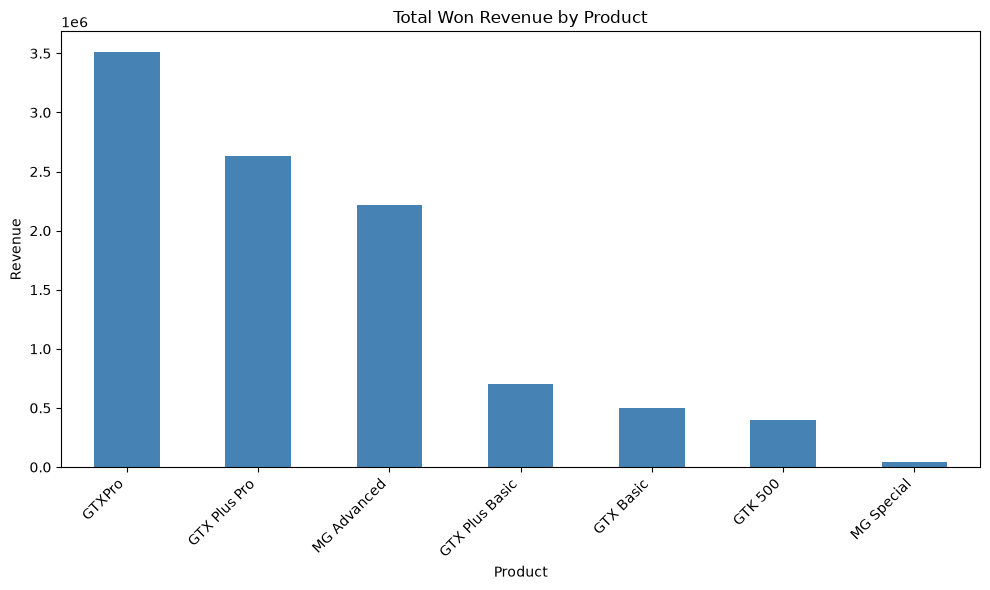

In [35]:
# Revenue by Product

import matplotlib.pyplot as plt

product_revenue = (
    sales[sales["deal_stage"] == "Won"]
    .groupby("product")["close_value"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
product_revenue.plot(kind="bar", color="steelblue")

plt.title("Total Won Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

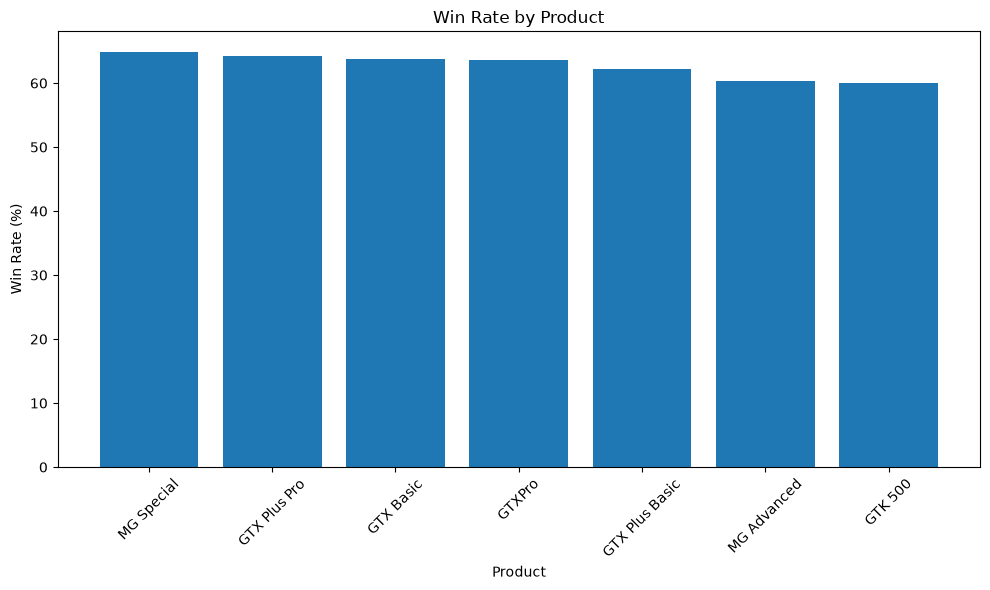

In [36]:
# Win rate for each product

# Keep only deals that were won or lost
closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

# Count won and lost deals for each product
product_wins = closed_sales[closed_sales["deal_stage"] == "Won"].groupby("product").size()
product_closed = closed_sales.groupby("product").size()

# Calculate win rate as a percentage
product_win_rate = (product_wins / product_closed) * 100

# Sort products from highest to lowest win rate
product_win_rate = product_win_rate.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.bar(product_win_rate.index, product_win_rate.values)

plt.title("Win Rate by Product")
plt.xlabel("Product")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

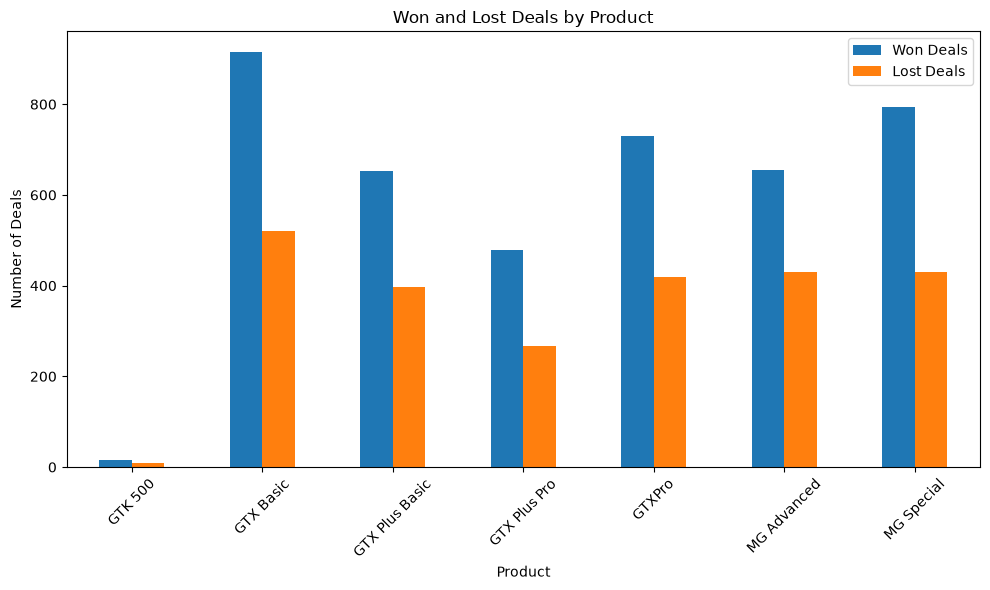

In [39]:
# Count won and lost deals for each product

# Keep only closed deals
closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

# Count won deals for each product
won_count = closed_sales[
    closed_sales["deal_stage"] == "Won"
].groupby("product").size()

# Count lost deals for each product
lost_count = closed_sales[
    closed_sales["deal_stage"] == "Lost"
].groupby("product").size()

# Combine both counts into one table
product_deals = pd.DataFrame({
    "Won Deals": won_count,
    "Lost Deals": lost_count
})

# Replace missing counts with zero
product_deals = product_deals.fillna(0)

# Create a chart
product_deals.plot(kind="bar", figsize=(10, 6))

plt.title("Won and Lost Deals by Product")
plt.xlabel("Product")
plt.ylabel("Number of Deals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

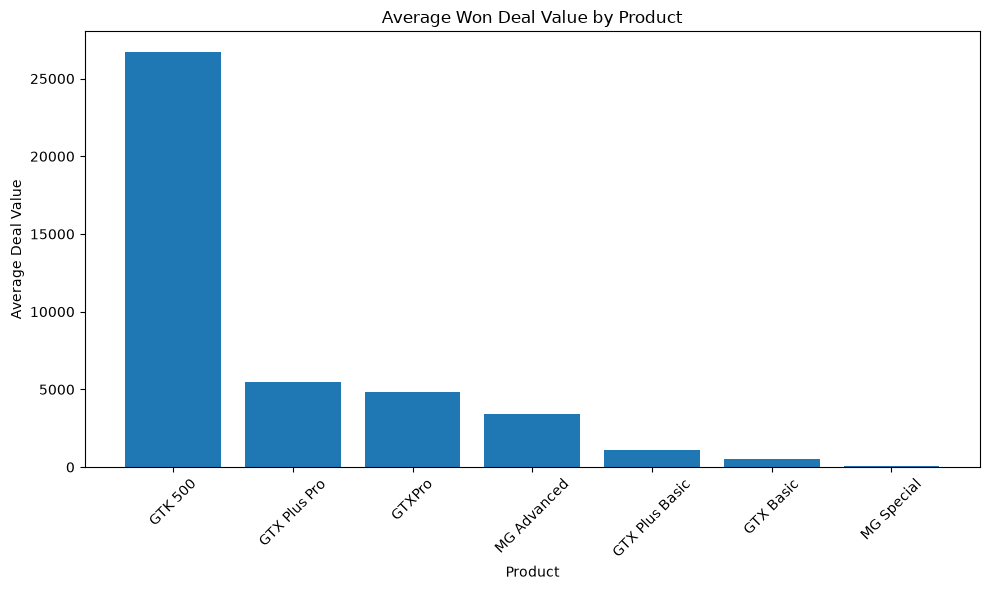

In [40]:
# Average value of won deals for each product

# Keep only won deals
won_sales = sales[sales["deal_stage"] == "Won"]

# Calculate average deal value for each product
average_deal_value = won_sales.groupby("product")["close_value"].mean()

# Sort products from highest to lowest average value
average_deal_value = average_deal_value.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.bar(average_deal_value.index, average_deal_value.values)

plt.title("Average Won Deal Value by Product")
plt.xlabel("Product")
plt.ylabel("Average Deal Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

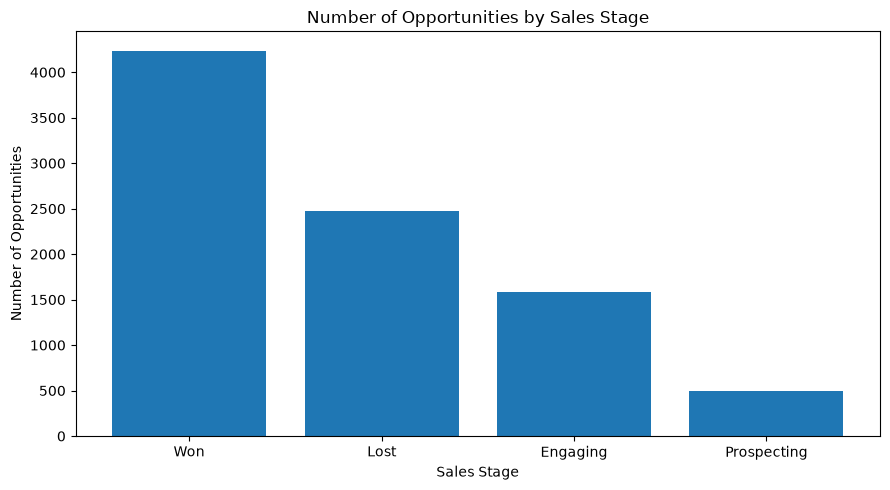

In [41]:
# Count opportunities in each sales stage

stage_counts = sales["deal_stage"].value_counts()

# Create a bar chart
plt.figure(figsize=(9, 5))
plt.bar(stage_counts.index, stage_counts.values)

plt.title("Number of Opportunities by Sales Stage")
plt.xlabel("Sales Stage")
plt.ylabel("Number of Opportunities")
plt.tight_layout()
plt.show()

In [42]:
# Count missing values in each column
missing_values = sales.isnull().sum()

# Calculate missing values as a percentage
missing_percentage = (missing_values / len(sales)) * 100

# Combine the results into a table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Keep only columns that contain missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

# Sort by the number of missing values
missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

# Display the results
missing_summary

,Missing Values,Missing Percentage
close_date,2089,23.738636
close_value,2089,23.738636
account,1425,16.193182
engage_date,500,5.681818


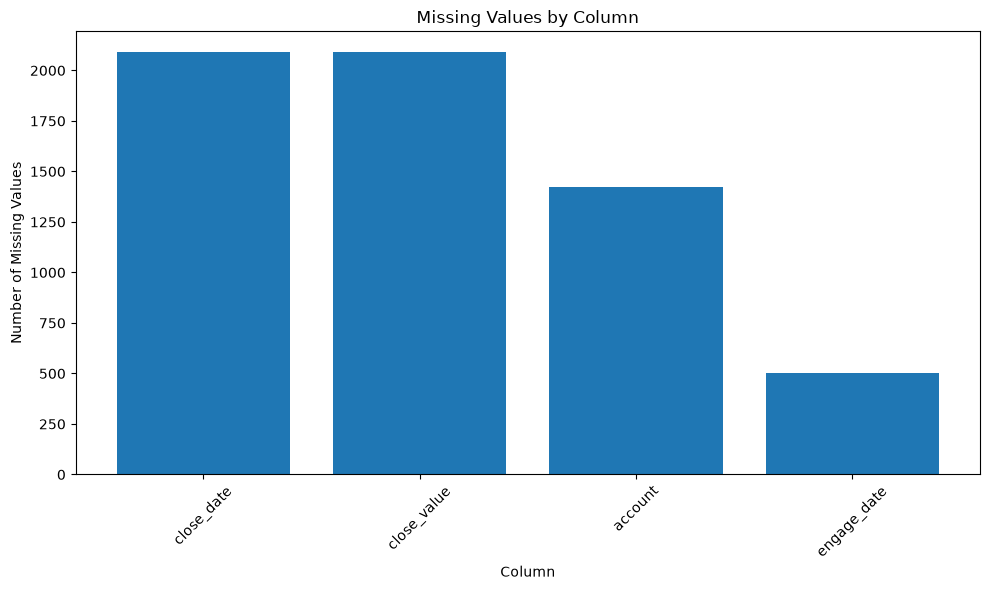

In [43]:
# Visualise missing values in each column

plt.figure(figsize=(10, 6))

plt.bar(
    missing_summary.index,
    missing_summary["Missing Values"]
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# Calculate revenue contribution by product

# Keep only won deals
won_sales = sales[sales["deal_stage"] == "Won"]

# Calculate total revenue for each product
product_revenue = won_sales.groupby("product")["close_value"].sum()

# Calculate each product's percentage of total revenue
revenue_percentage = (
    product_revenue / product_revenue.sum()
) * 100

# Combine revenue and percentage into a table
revenue_summary = pd.DataFrame({
    "Total Revenue": product_revenue,
    "Revenue Percentage": revenue_percentage
})

# Sort products by total revenue
revenue_summary = revenue_summary.sort_values(
    by="Total Revenue",
    ascending=False
)

# Display the results
revenue_summary.round(2)

,Total Revenue,Revenue Percentage
product,,
GTXPro,3510578.0,35.09
GTX Plus Pro,2629651.0,26.28
MG Advanced,2216387.0,22.15
GTX Plus Basic,705275.0,7.05
GTX Basic,499263.0,4.99
GTK 500,400612.0,4.00
MG Special,43768.0,0.44


In [45]:
# Final checks for the sales analysis project

# Check the dataset size
print("Total opportunities:", len(sales))

# Check the number of won deals
print("Won deals:", (sales["deal_stage"] == "Won").sum())

# Check the number of lost deals
print("Lost deals:", (sales["deal_stage"] == "Lost").sum())

# Calculate total won revenue
total_revenue = sales.loc[
    sales["deal_stage"] == "Won",
    "close_value"
].sum()

print("Total won revenue:", round(total_revenue, 2))

# Check for duplicate opportunity IDs
print(
    "Duplicate opportunity IDs:",
    sales["opportunity_id"].duplicated().sum()
)

# Check whether all won deals have a closing value
won_sales = sales[sales["deal_stage"] == "Won"]

print(
    "Won deals with missing closing value:",
    won_sales["close_value"].isnull().sum()
)

Total opportunities: 8800
Won deals: 4238
Lost deals: 2473
Total won revenue: 10005534.0
Duplicate opportunity IDs: 0
Won deals with missing closing value: 0


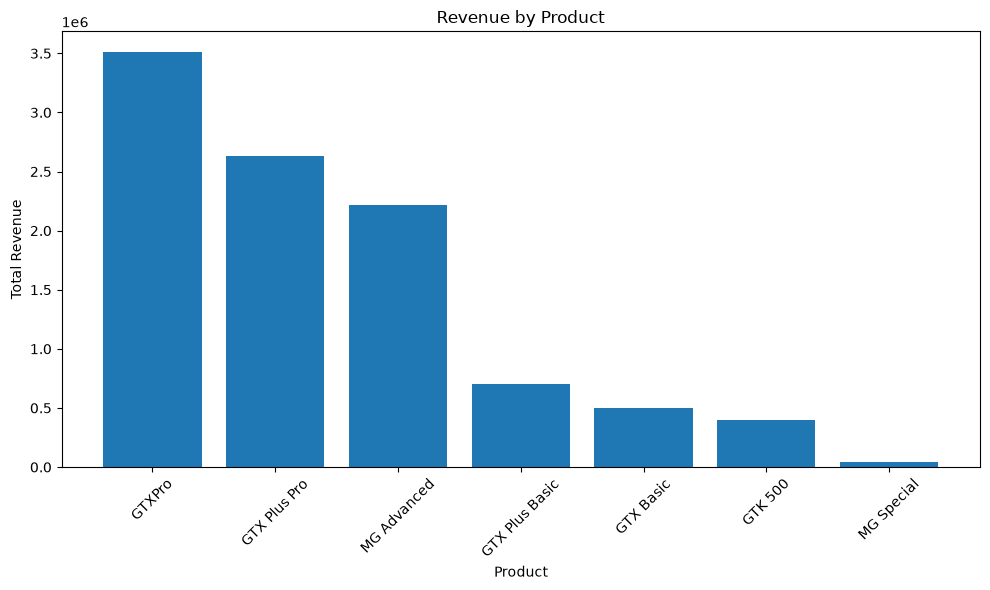

In [46]:
# Save the revenue by product chart

won_sales = sales[sales["deal_stage"] == "Won"]

product_revenue = won_sales.groupby("product")["close_value"].sum()
product_revenue = product_revenue.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(product_revenue.index, product_revenue.values)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../outputs/revenue_by_product.png", dpi=300)
plt.show()

In [47]:
# Create folders for project outputs

import os

os.makedirs("../outputs", exist_ok=True)
os.makedirs("../outputs/figures", exist_ok=True)

print("Project output folders are ready.")

Project output folders are ready.


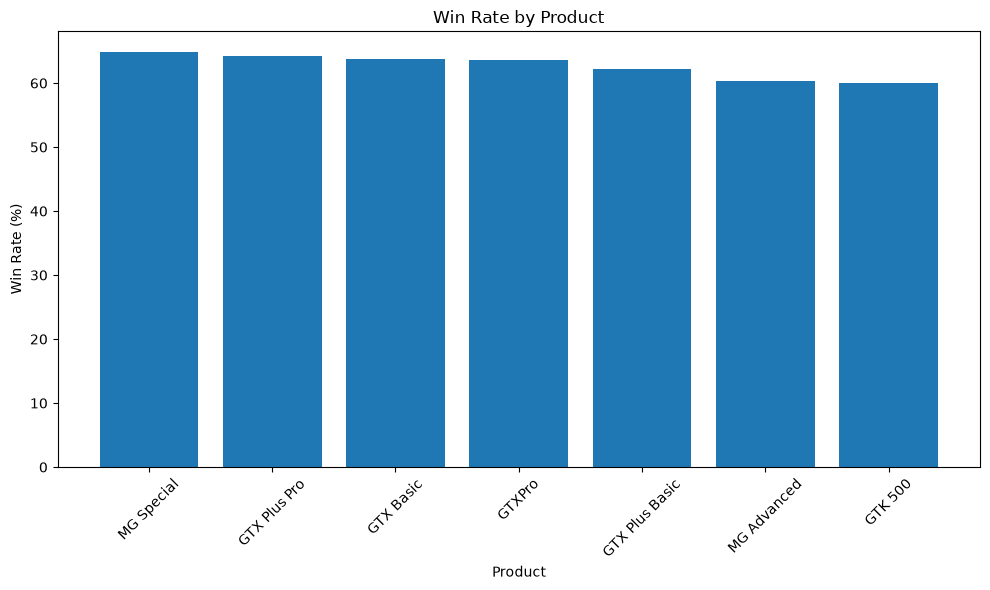

In [48]:
# Save win rate by product

closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

product_wins = closed_sales[
    closed_sales["deal_stage"] == "Won"
].groupby("product").size()

product_closed = closed_sales.groupby("product").size()

product_win_rate = (product_wins / product_closed) * 100
product_win_rate = product_win_rate.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(product_win_rate.index, product_win_rate.values)

plt.title("Win Rate by Product")
plt.xlabel("Product")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../outputs/figures/win_rate_by_product.png", dpi=300)
plt.show()

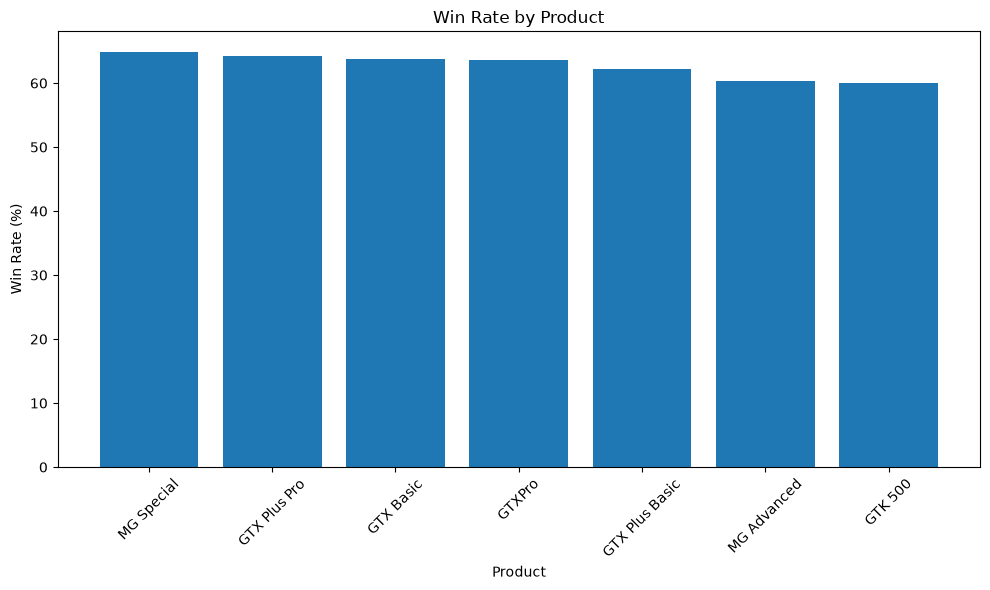

In [49]:
# Save win rate by product

closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

product_wins = closed_sales[
    closed_sales["deal_stage"] == "Won"
].groupby("product").size()

product_closed = closed_sales.groupby("product").size()

product_win_rate = (product_wins / product_closed) * 100
product_win_rate = product_win_rate.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(product_win_rate.index, product_win_rate.values)

plt.title("Win Rate by Product")
plt.xlabel("Product")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../outputs/figures/win_rate_by_product.png", dpi=300)
plt.show()

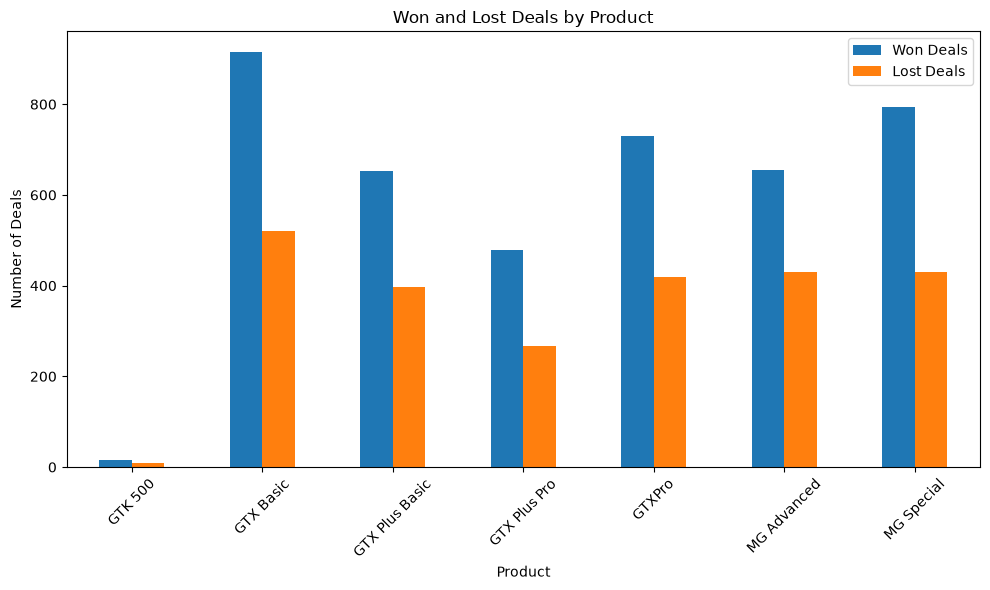

In [50]:
# Save won and lost deals by product

closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

won_count = closed_sales[
    closed_sales["deal_stage"] == "Won"
].groupby("product").size()

lost_count = closed_sales[
    closed_sales["deal_stage"] == "Lost"
].groupby("product").size()

product_deals = pd.DataFrame({
    "Won Deals": won_count,
    "Lost Deals": lost_count
})

product_deals = product_deals.fillna(0)

product_deals.plot(kind="bar", figsize=(10, 6))

plt.title("Won and Lost Deals by Product")
plt.xlabel("Product")
plt.ylabel("Number of Deals")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/won_lost_deals_by_product.png",
    dpi=300
)

plt.show()

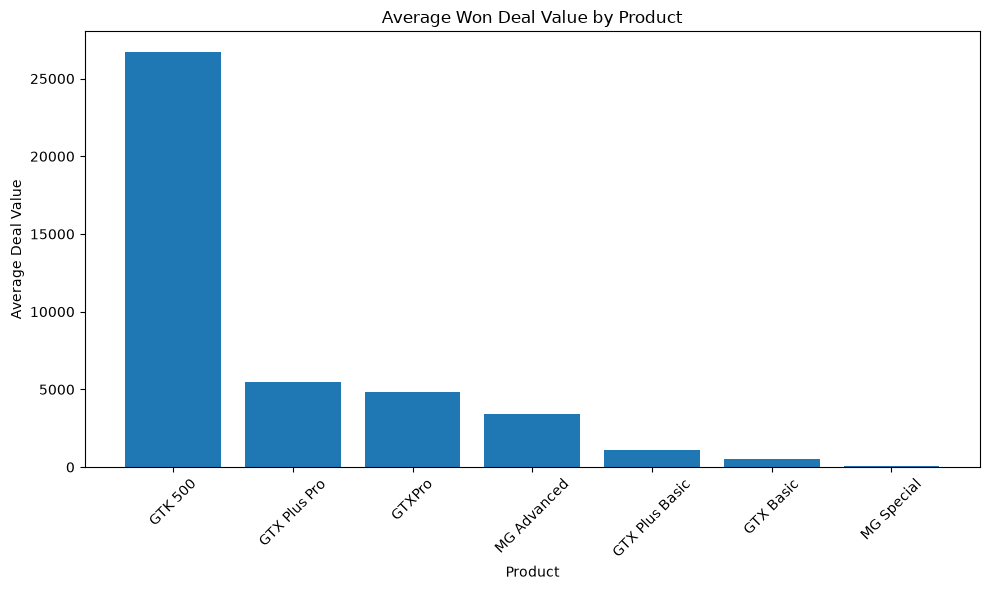

In [51]:
# Save average won deal value by product

won_sales = sales[sales["deal_stage"] == "Won"]

average_deal_value = won_sales.groupby("product")["close_value"].mean()
average_deal_value = average_deal_value.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(average_deal_value.index, average_deal_value.values)

plt.title("Average Won Deal Value by Product")
plt.xlabel("Product")
plt.ylabel("Average Deal Value")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/average_deal_value_by_product.png",
    dpi=300
)

plt.show()

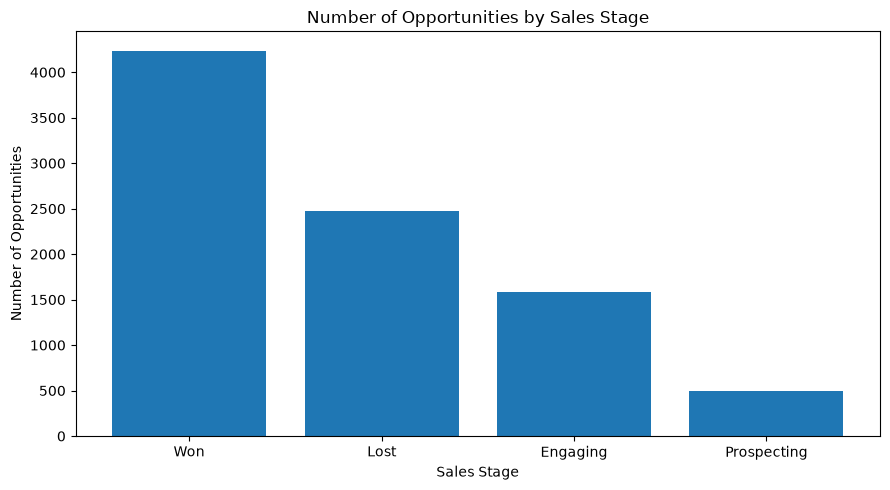

In [52]:
# Save sales-stage distribution chart

stage_counts = sales["deal_stage"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(stage_counts.index, stage_counts.values)

plt.title("Number of Opportunities by Sales Stage")
plt.xlabel("Sales Stage")
plt.ylabel("Number of Opportunities")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/sales_stage_distribution.png",
    dpi=300
)

plt.show()

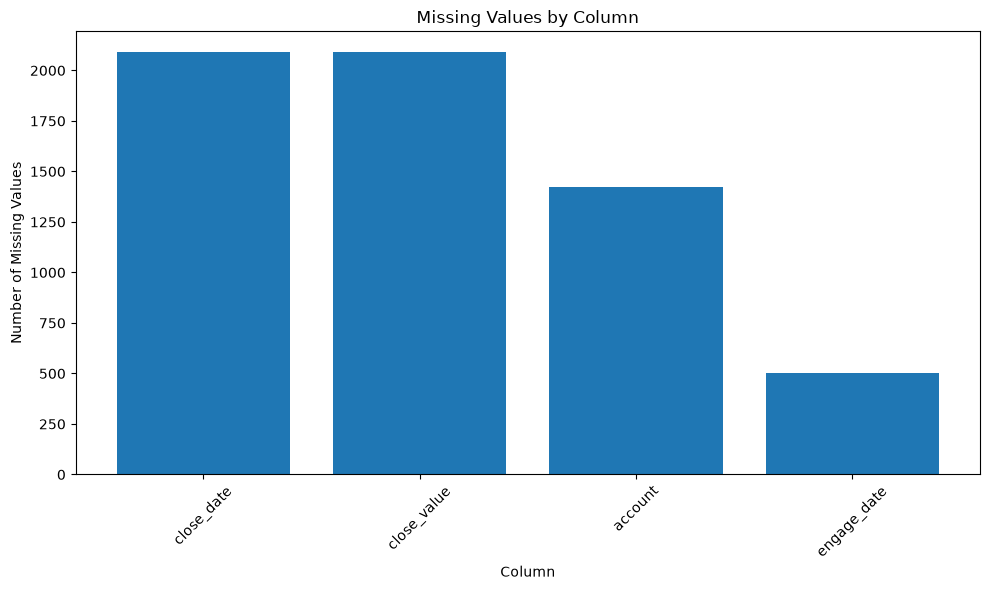

In [53]:
# Save the missing-values chart

plt.figure(figsize=(10, 6))

plt.bar(
    missing_summary.index,
    missing_summary["Missing Values"]
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/missing_values_by_column.png",
    dpi=300
)

plt.show()

In [54]:
# Check which chart files were saved

import os

chart_files = os.listdir("../outputs/figures")

print("Saved chart files:")

for chart in chart_files:
    print(chart)

print("\nTotal chart files:", len(chart_files))

Saved chart files:
won_lost_deals_by_product.png
missing_values_by_column.png
average_deal_value_by_product.png
win_rate_by_product.png
sales_stage_distribution.png

Total chart files: 5


In [55]:
# Move the revenue chart into the figures folder

import os
import shutil

source_file = "../outputs/revenue_by_product.png"
destination_file = "../outputs/figures/revenue_by_product.png"

if os.path.exists(source_file):
    shutil.move(source_file, destination_file)
    print("Revenue chart moved successfully.")
elif os.path.exists(destination_file):
    print("Revenue chart is already in the figures folder.")
else:
    print("Revenue chart not found. We need to locate it.")

Revenue chart moved successfully.


In [56]:
# Verify all saved charts

chart_files = os.listdir("../outputs/figures")

for chart in sorted(chart_files):
    print(chart)

print("Total charts:", len(chart_files))

average_deal_value_by_product.png
missing_values_by_column.png
revenue_by_product.png
sales_stage_distribution.png
win_rate_by_product.png
won_lost_deals_by_product.png
Total charts: 6


# Sales Performance Analysis: Business Insights

## 1. Revenue by Product

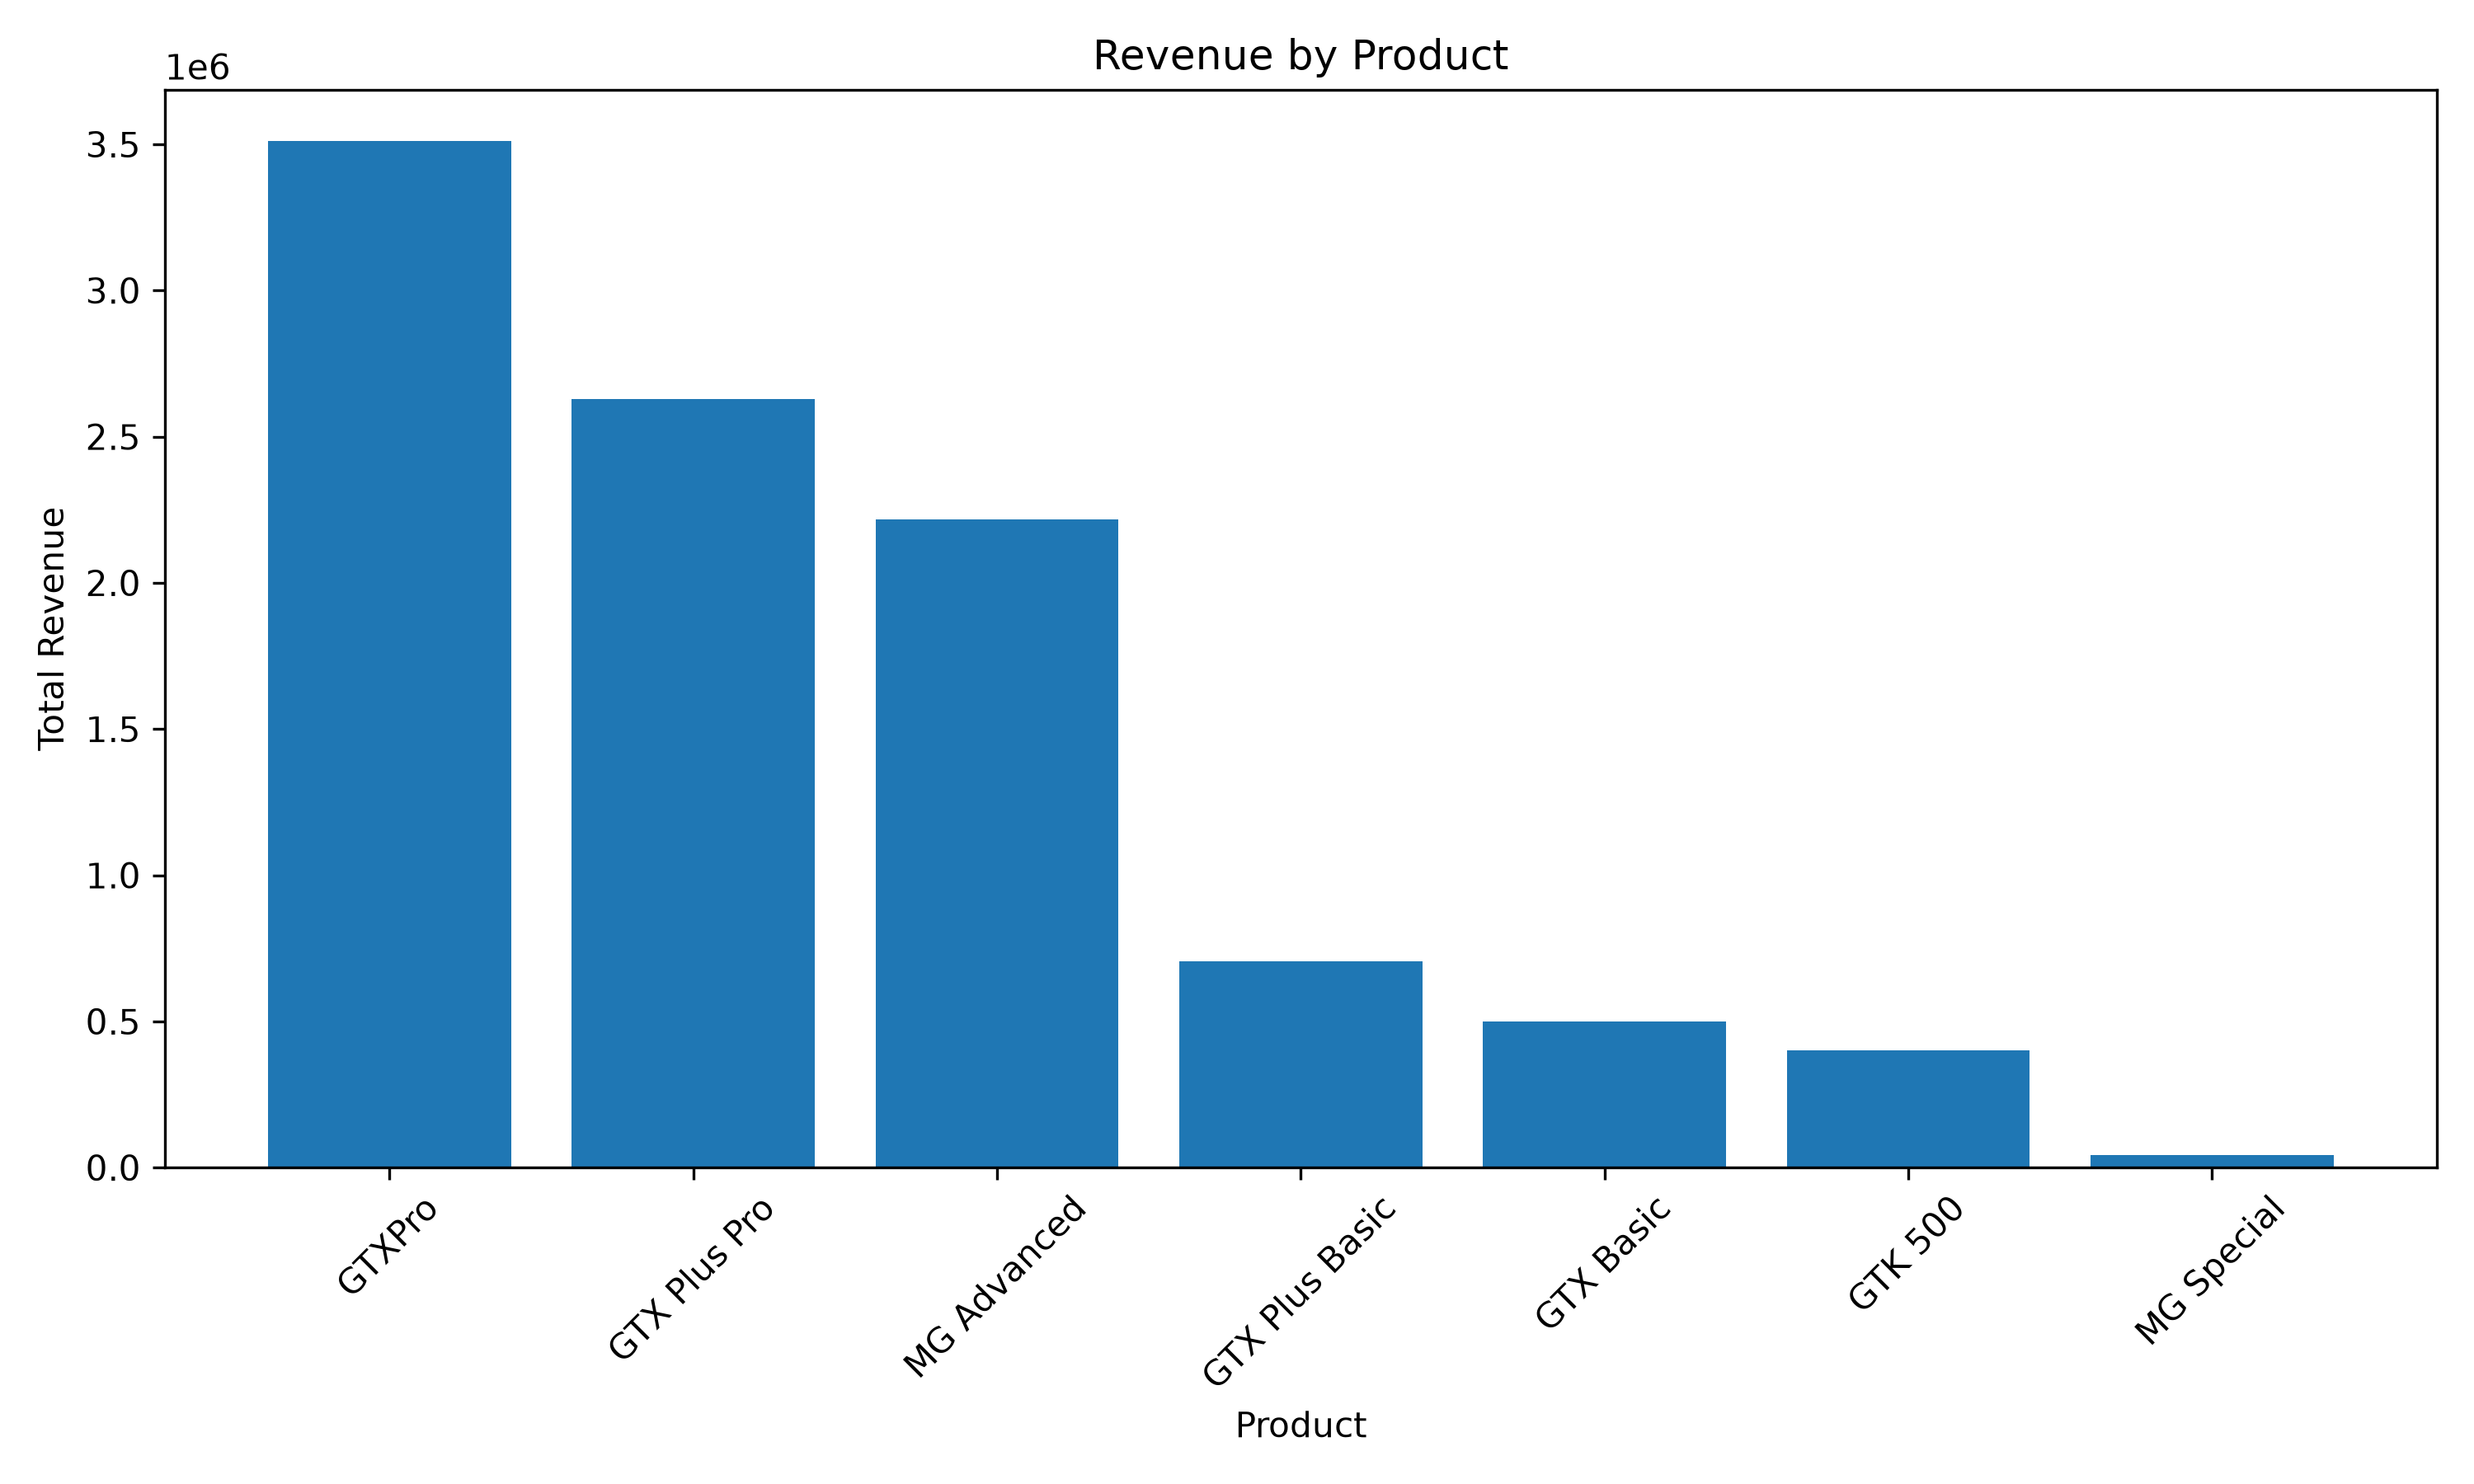

**Finding:** GTXPro generates the highest won revenue (3,510,578.00). The top three products contribute 83.52% of total won revenue.

**Business use:** Prioritise leading products in sales planning and investigate revenue concentration. Revenue is not the same as profit.

## 2. Win Rate by Product

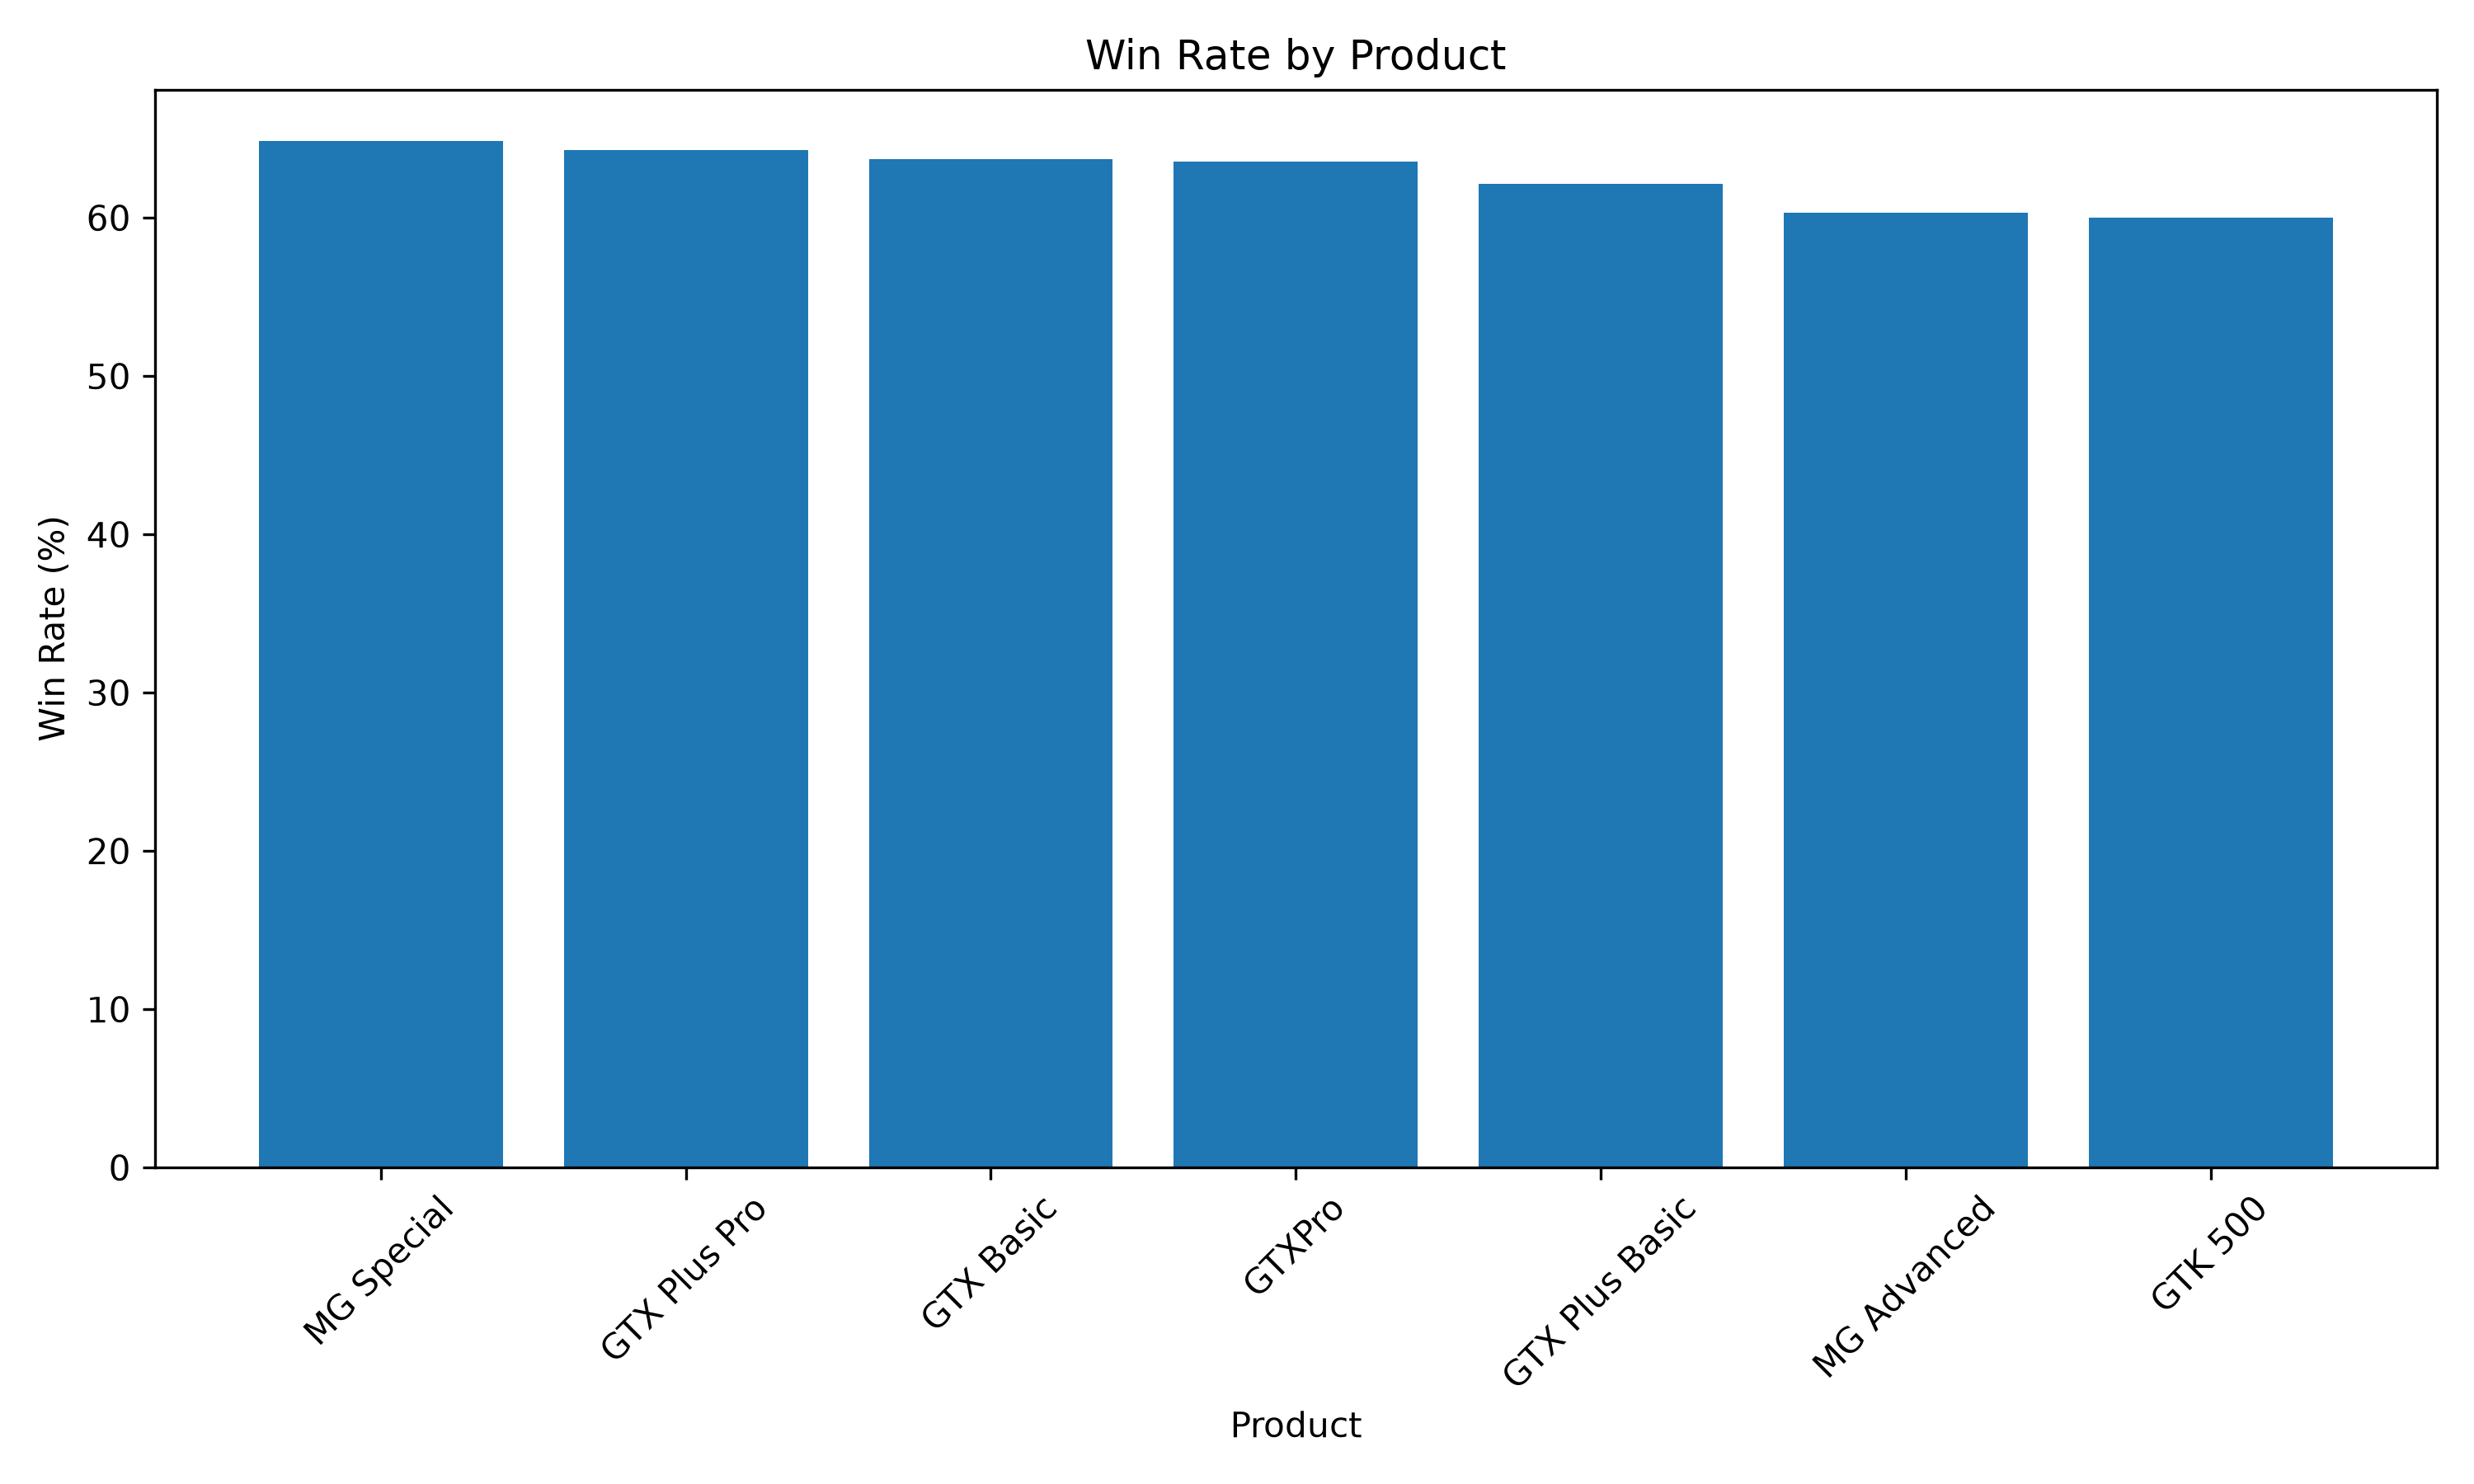

**Finding:** MG Special has the highest observed win rate at 64.84%.

**Business use:** Investigate differences in product conversion rates. Check the number of closed deals because small samples can mislead.

## 3. Won and Lost Deals by Product

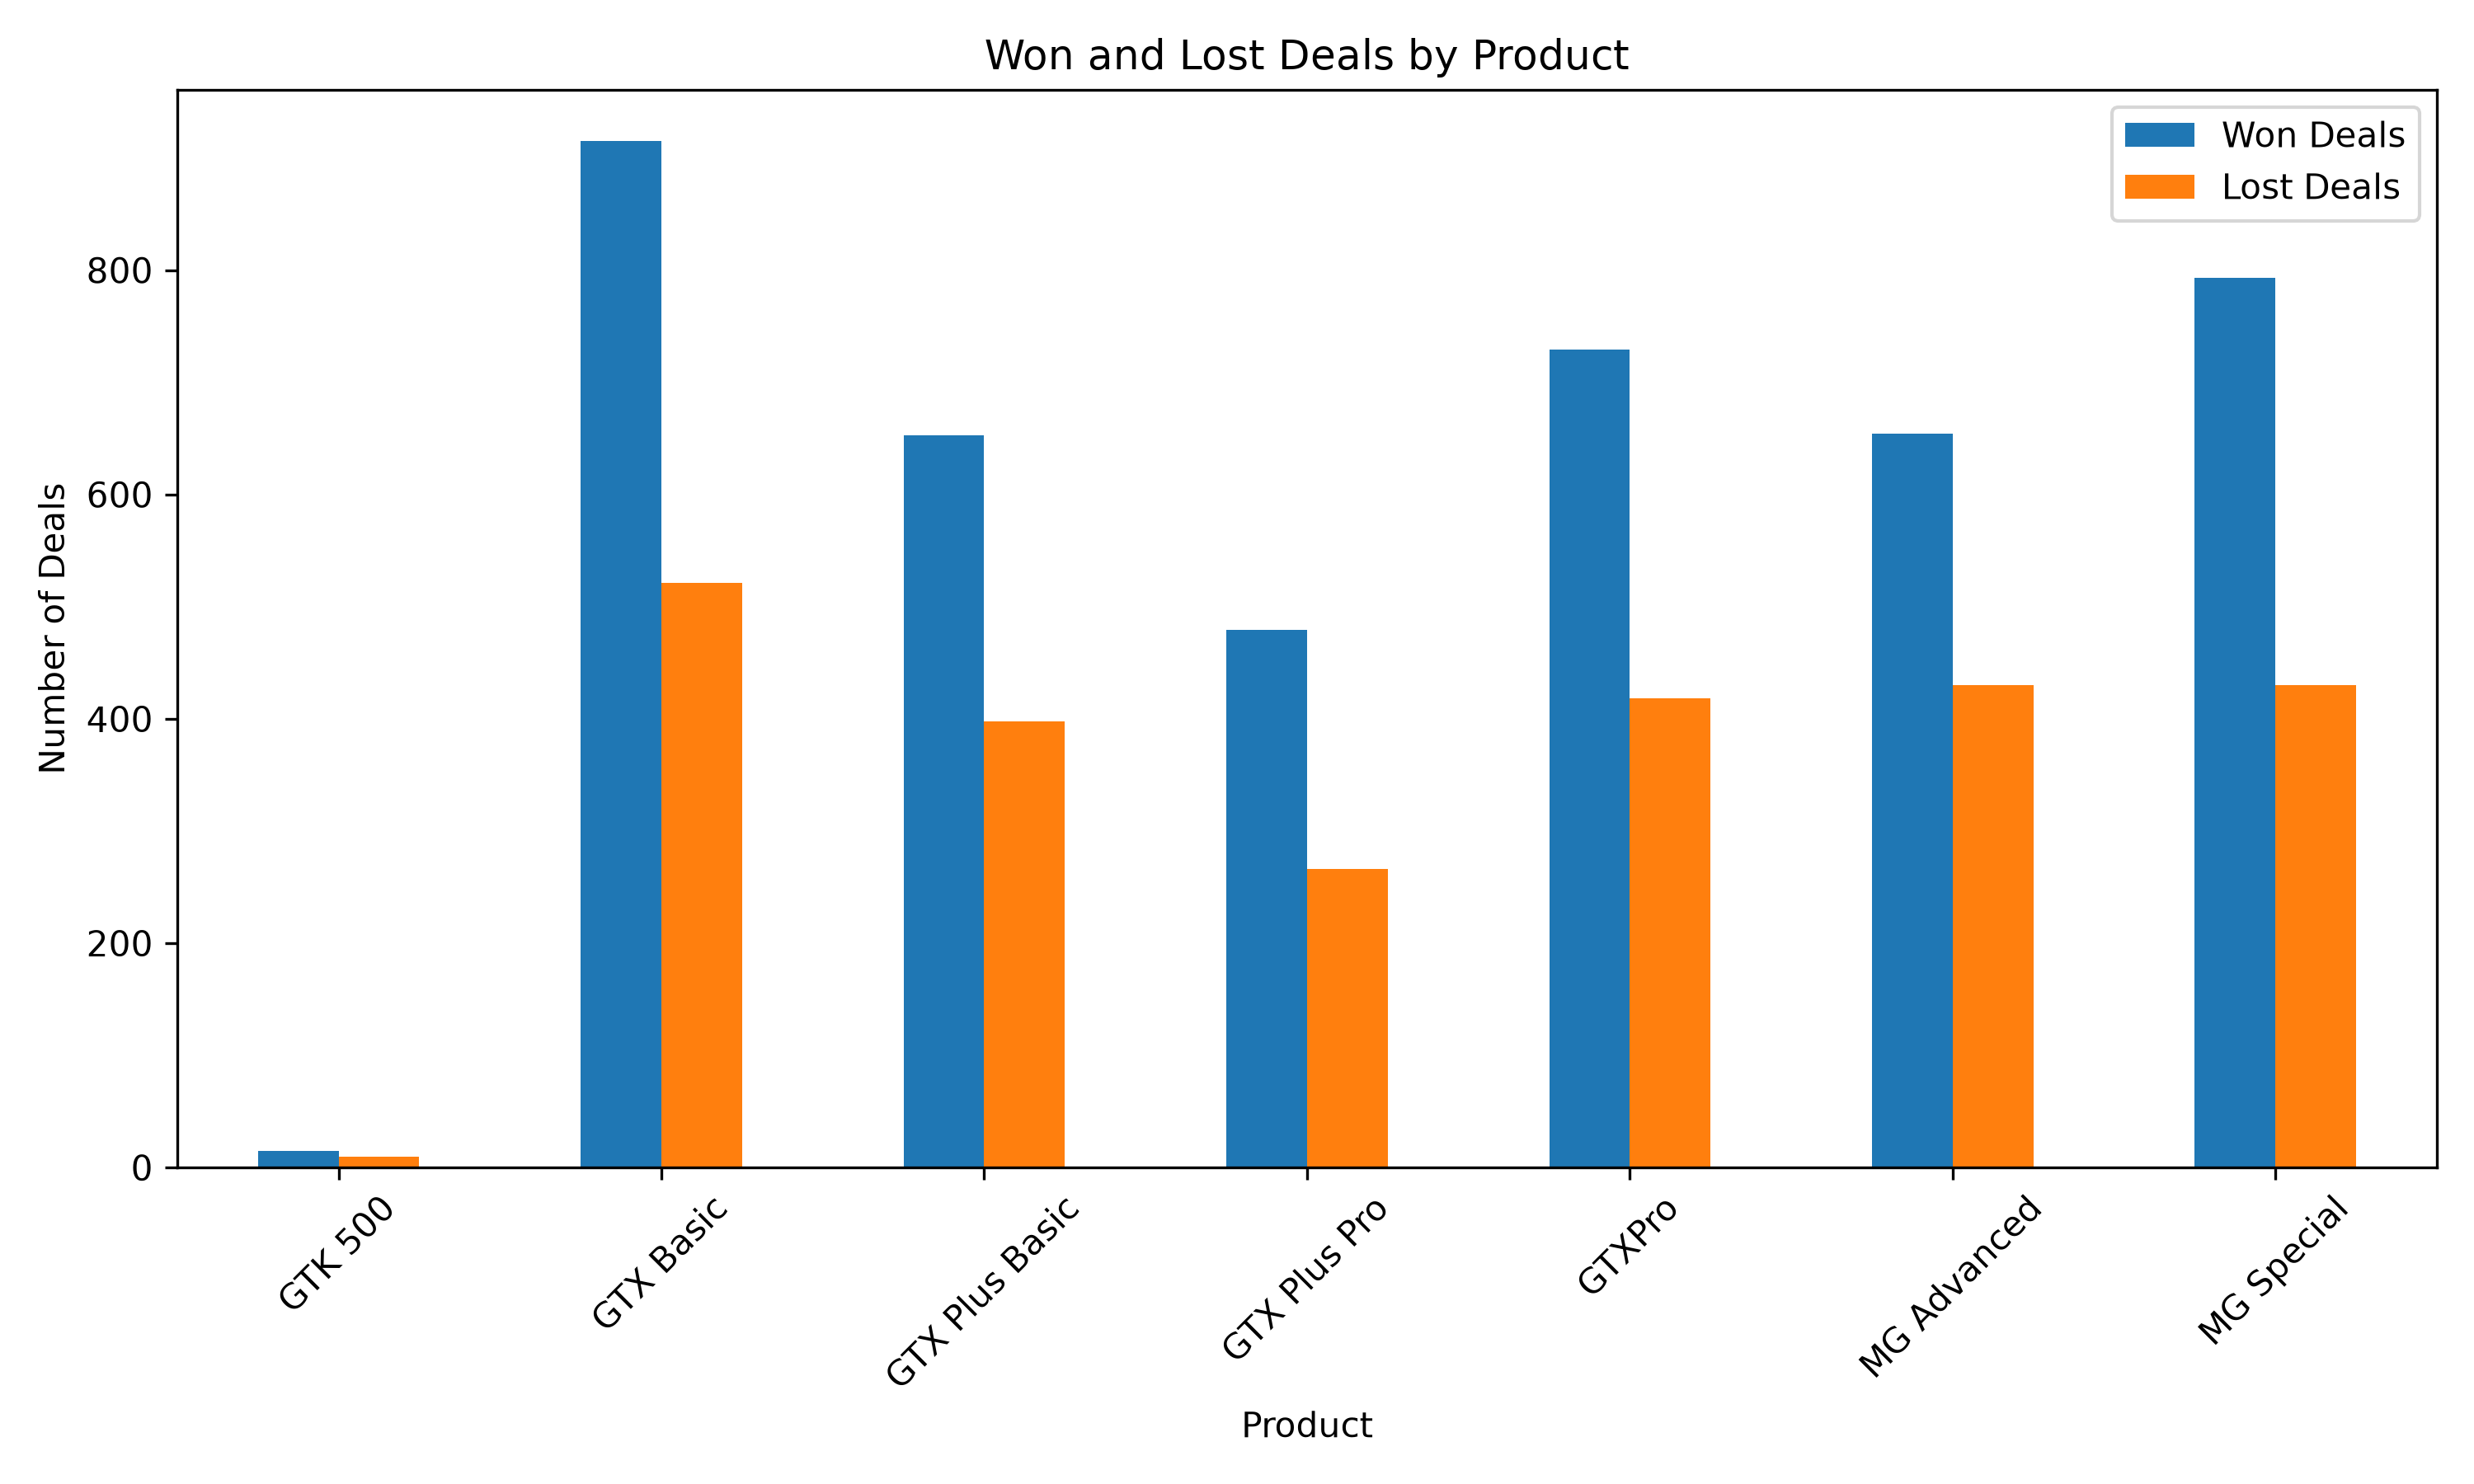

**Finding:** GTX Basic has the highest number of lost deals (521).

**Business use:** Investigate lost-deal reasons and compare loss counts with total closed deals. Counts alone do not explain why deals were lost.

## 4. Average Won Deal Value by Product

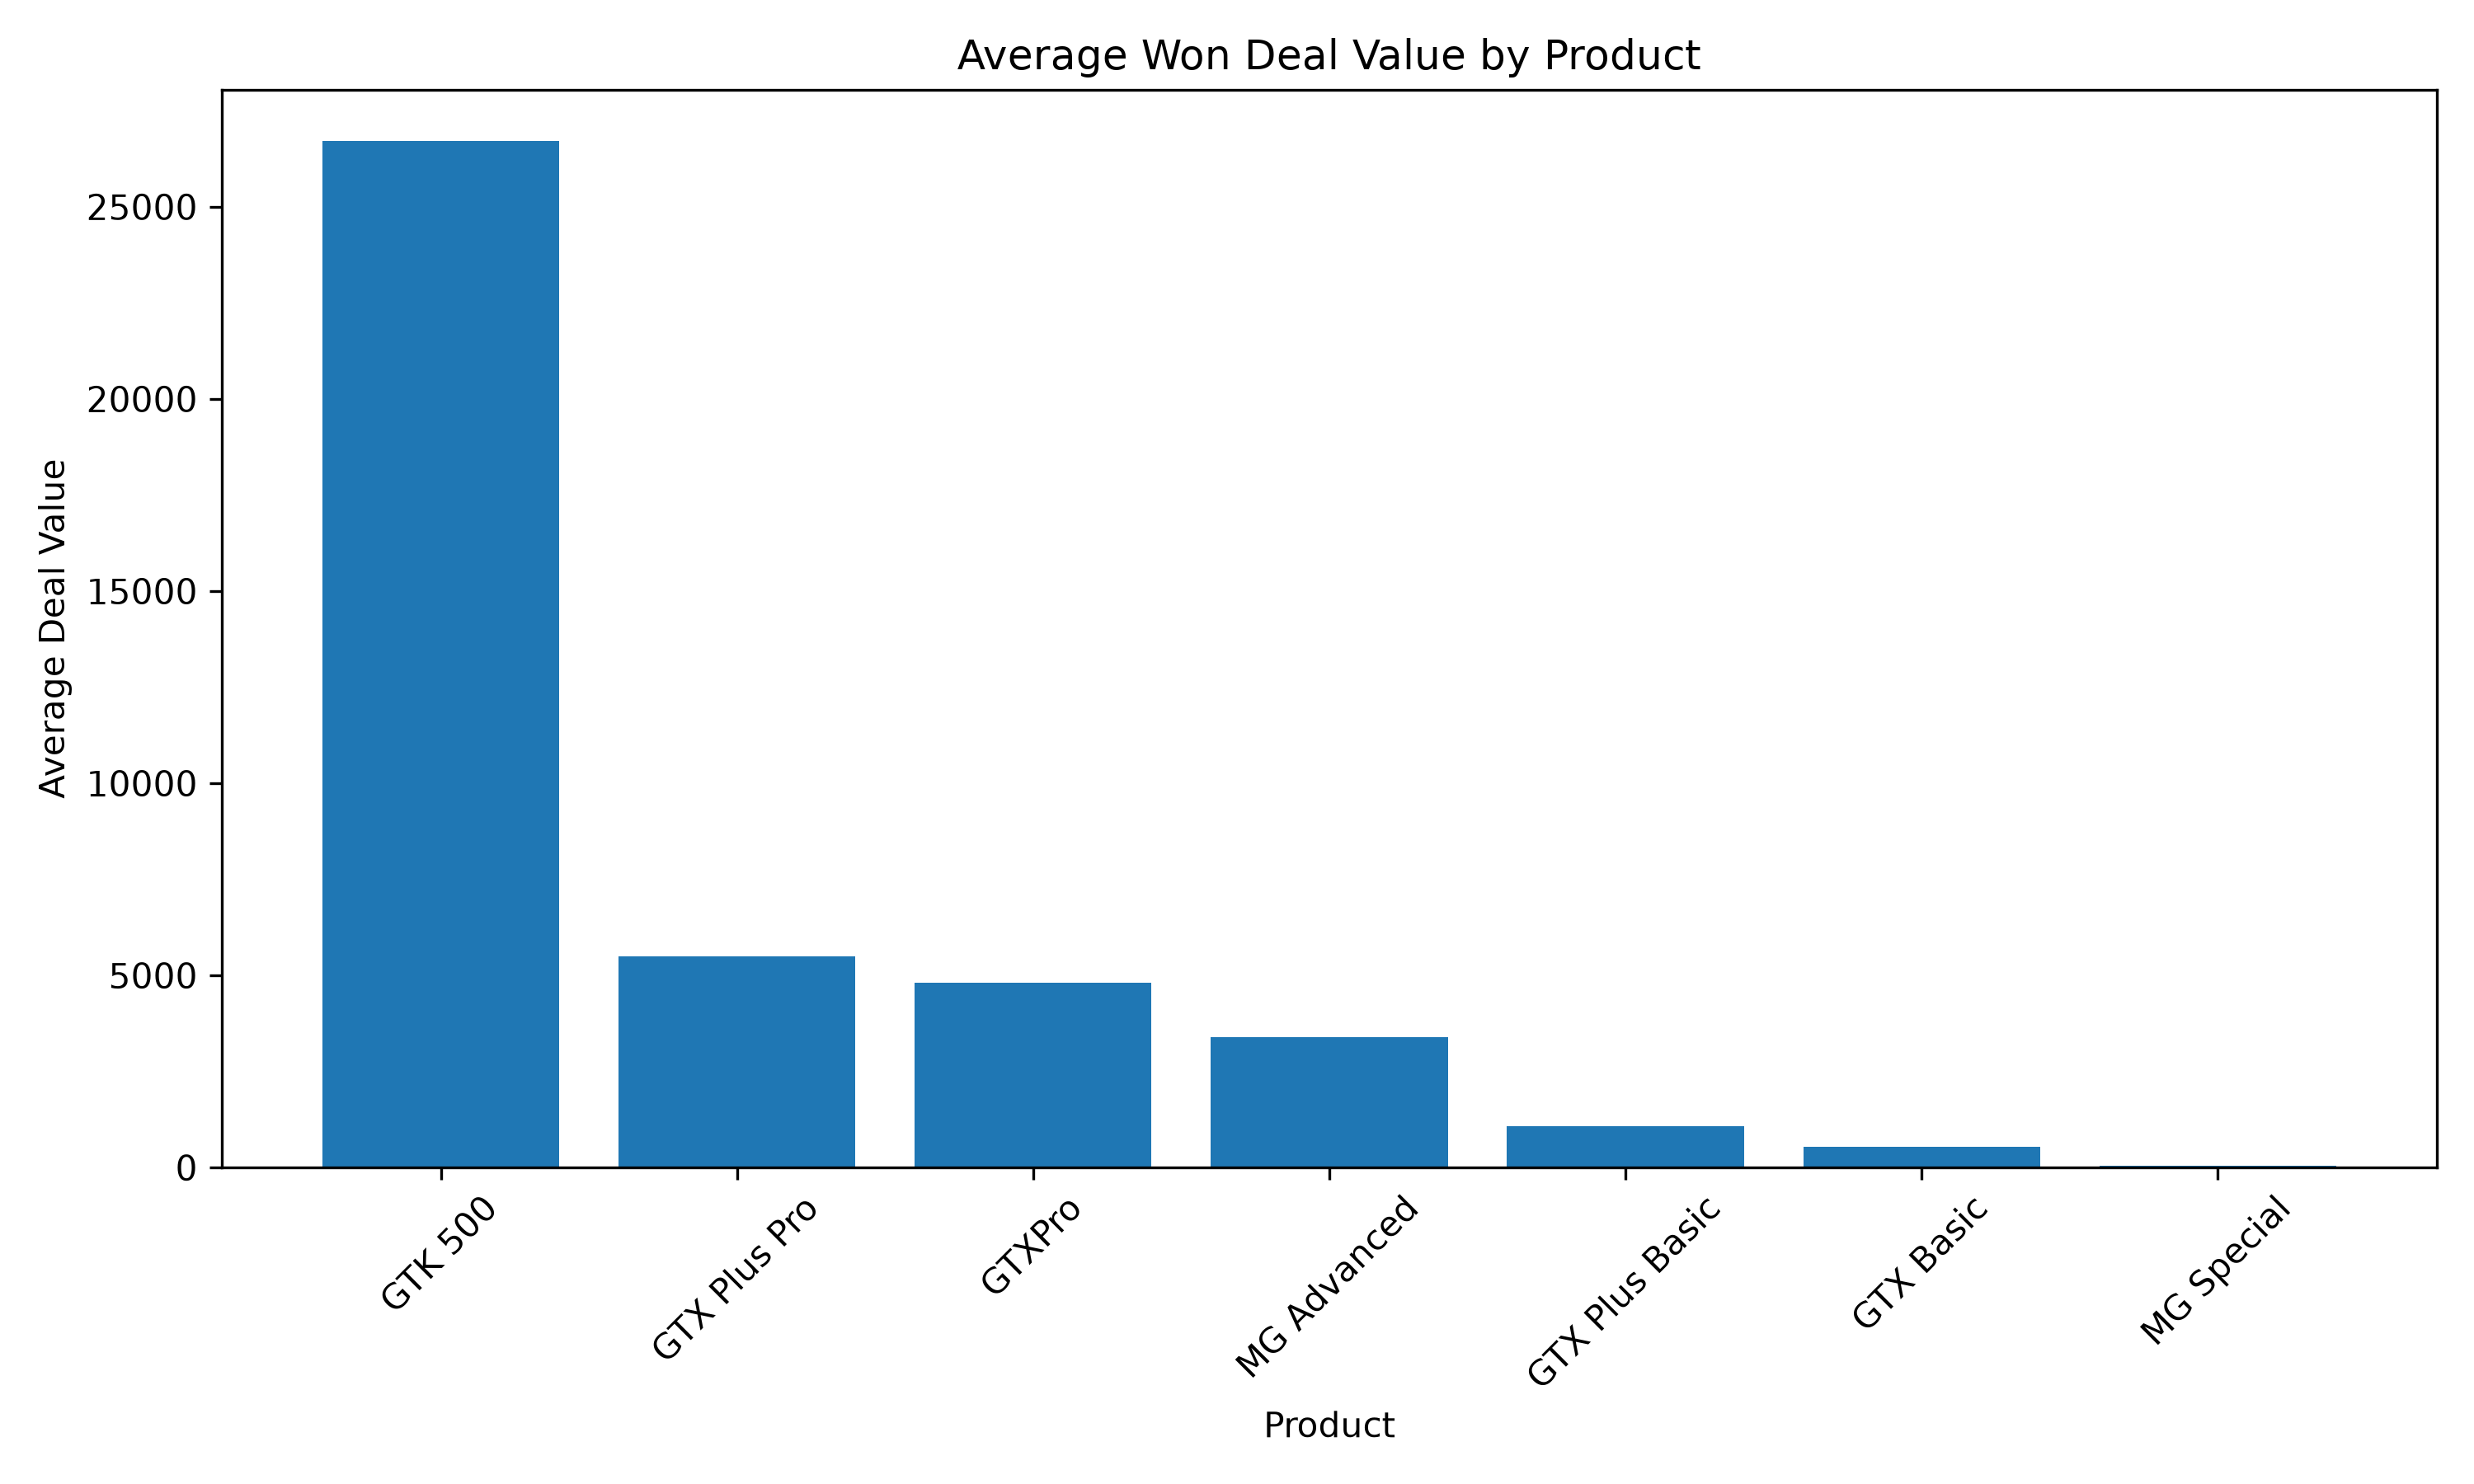

**Finding:** GTK 500 has the highest average won deal value (26,707.47).

**Business use:** Compare average deal values with revenue and win rates to support sales planning. A high average does not establish profitability.

## 5. Opportunities by Sales Stage

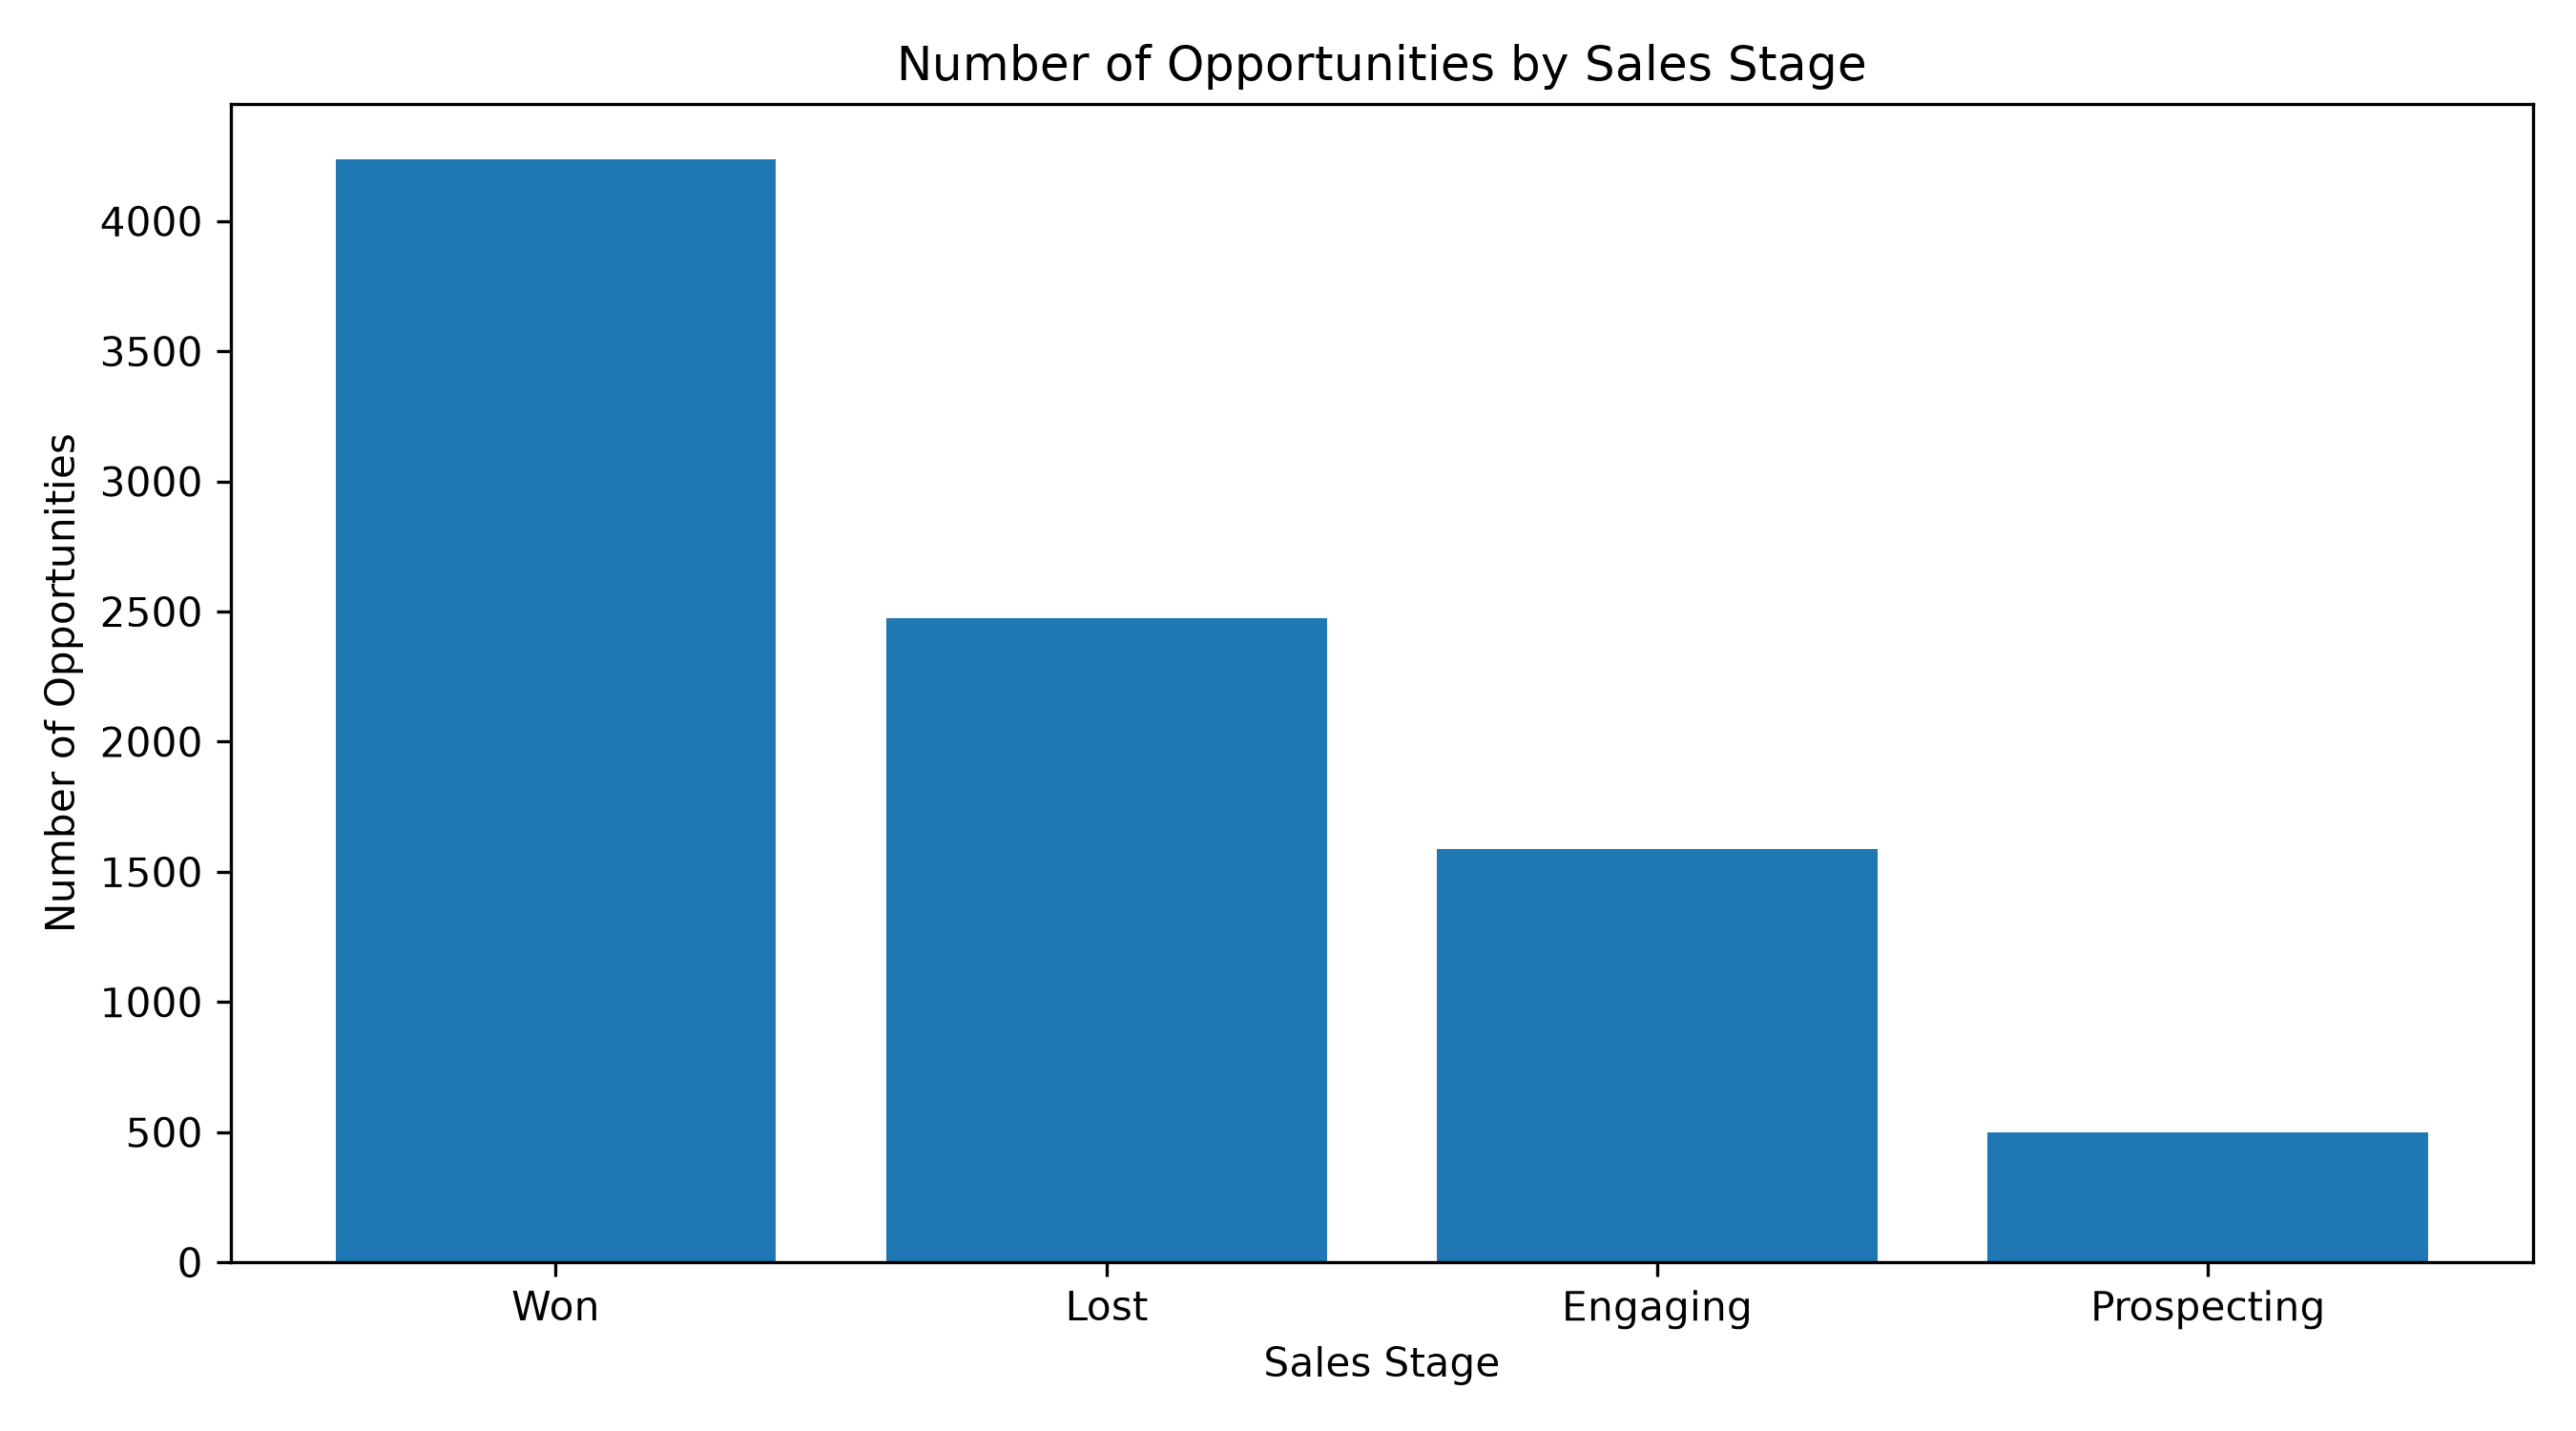

**Finding:** Distribution of all opportunities by stage:

- **Won:** 4,238 (48.16%)
- **Lost:** 2,473 (28.10%)
- **Engaging:** 1,589 (18.06%)
- **Prospecting:** 500 (5.68%)

**Business use:** Monitor pipeline composition and investigate conversion between stages. Counts alone do not show how long deals take.

## 6. Missing Values by Column

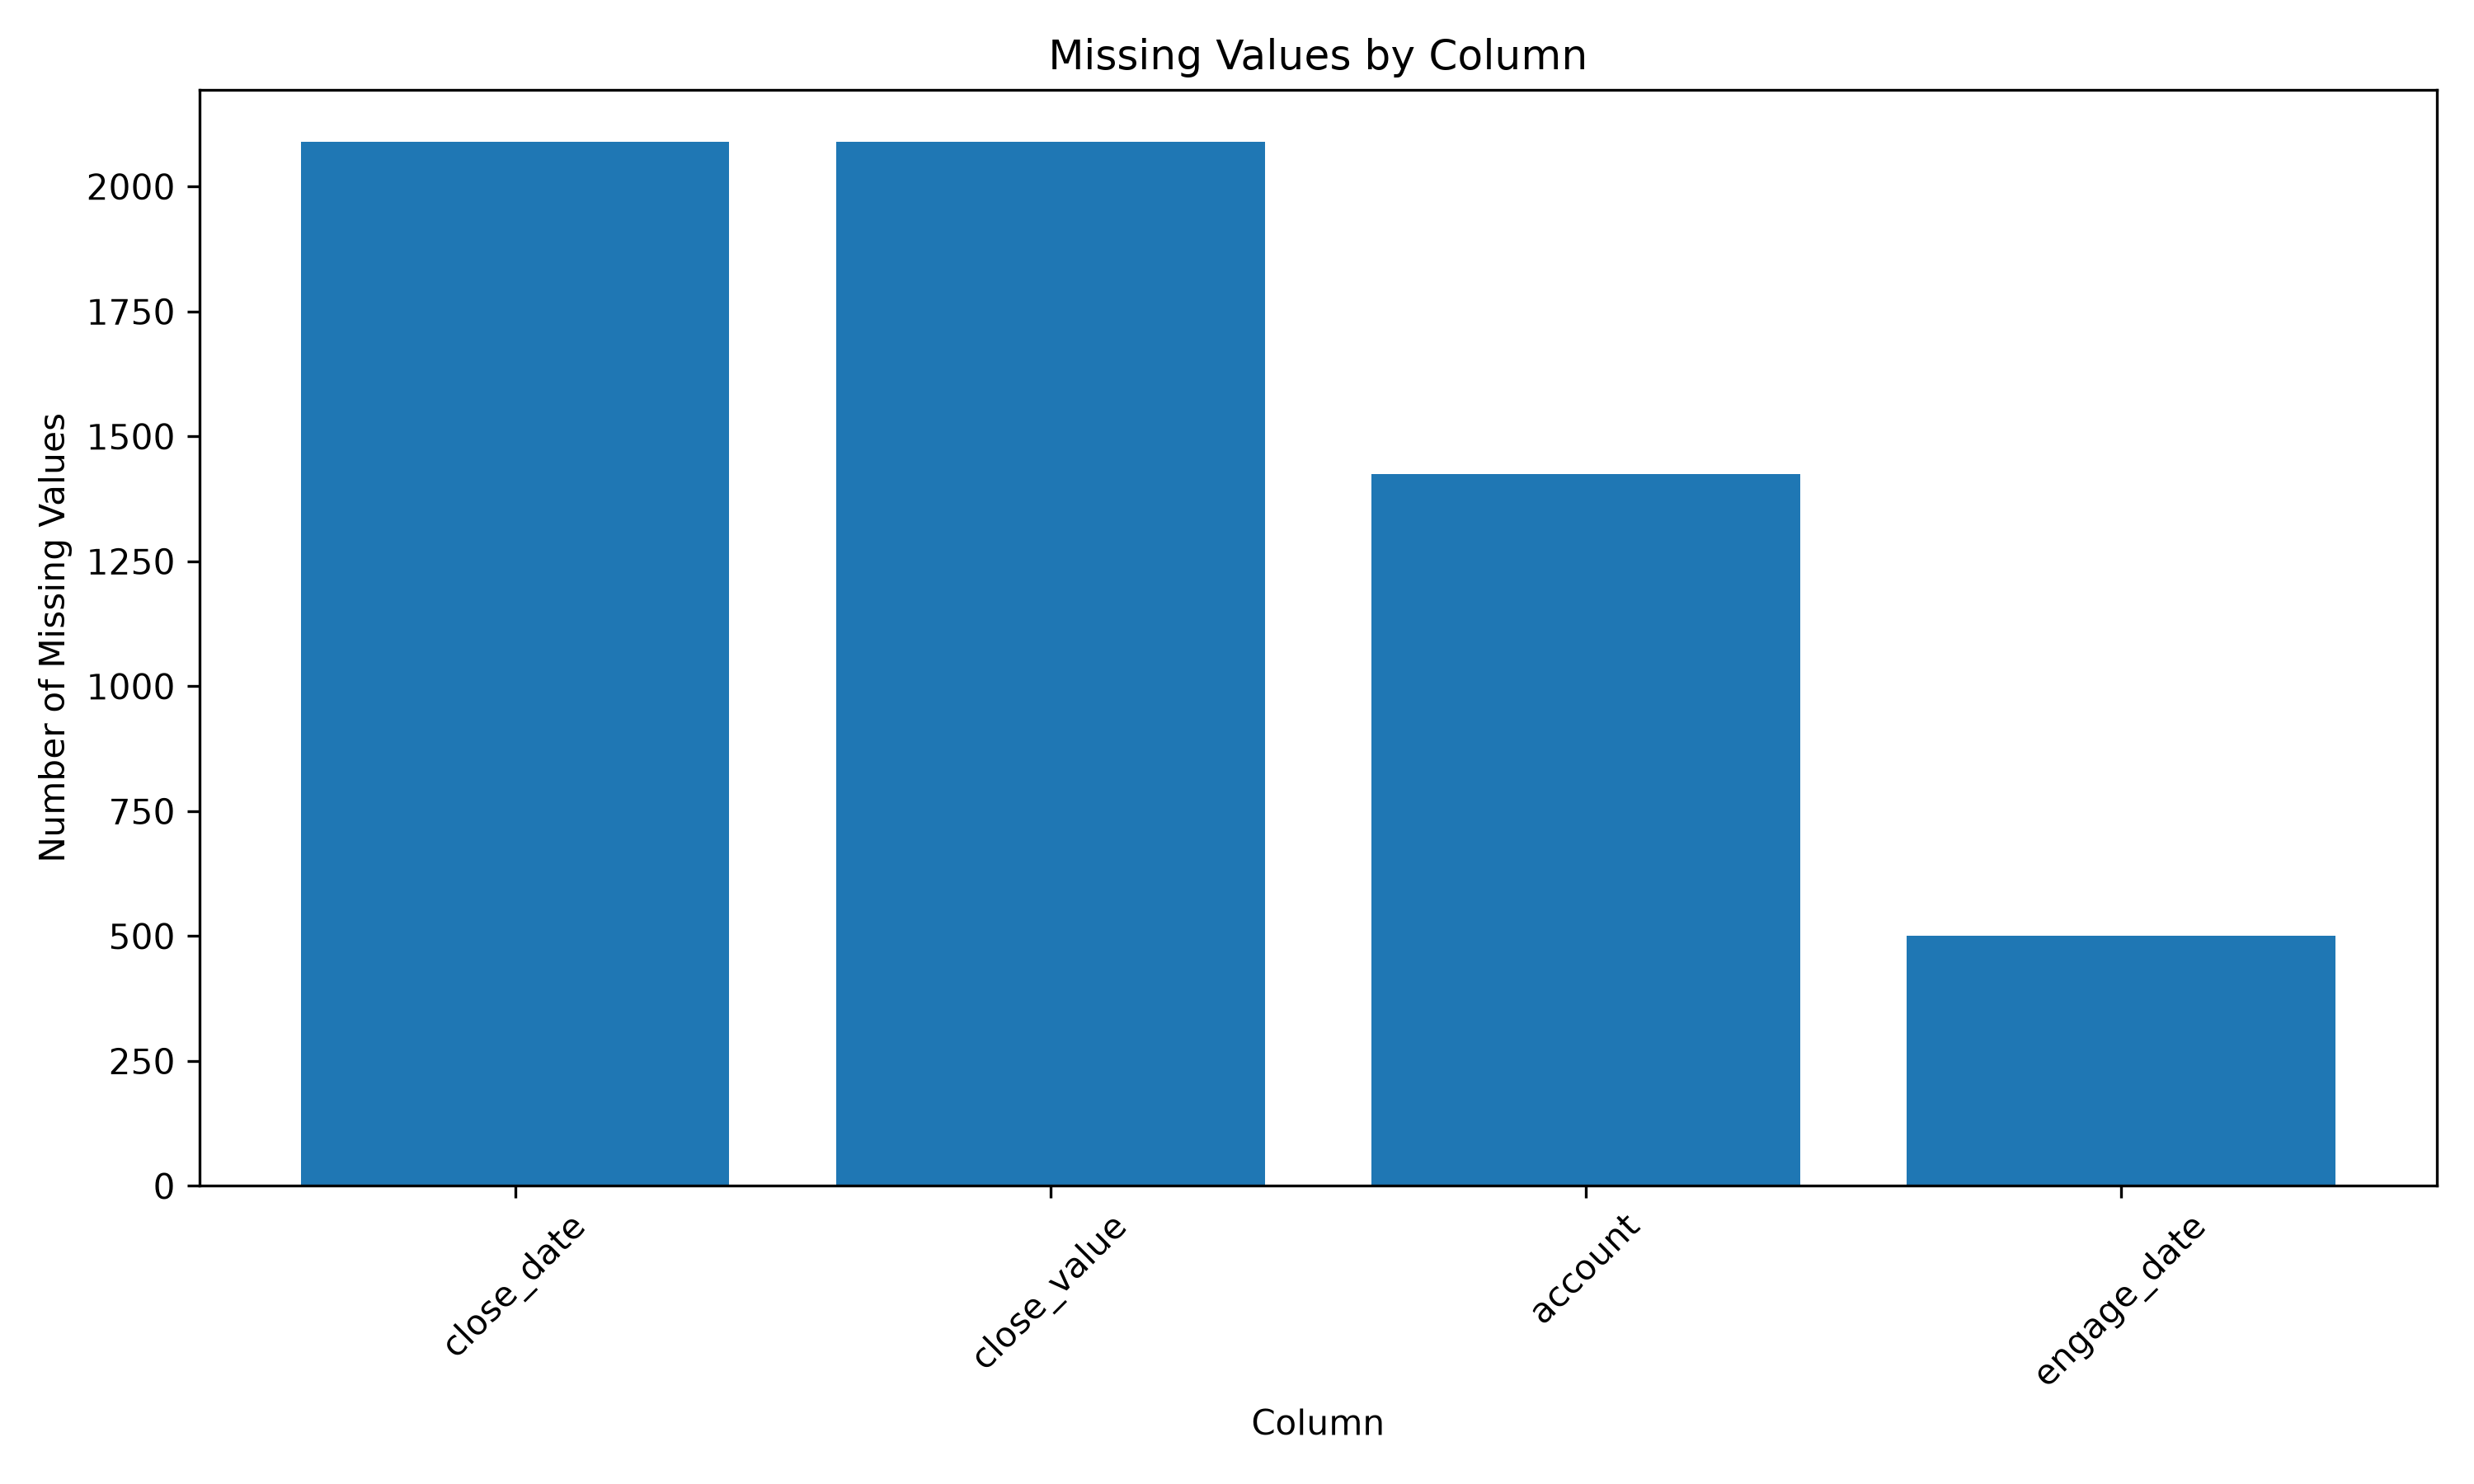

**Finding:** Missing values in the sales dataset:

- **close_date:** 2,089 missing (23.74%)
- **close_value:** 2,089 missing (23.74%)
- **account:** 1,425 missing (16.19%)
- **engage_date:** 500 missing (5.68%)

**Business use:** Investigate whether missing fields are expected or indicate data-entry problems before changing or excluding records.

## Overall Business Summary

- **Closed-deal win rate:** 63.15%
- **Total won revenue:** 10,005,534.00 recorded value units
- **Top-three product revenue contribution:** 83.52%

**Recommended actions:** Investigate lost-deal reasons, compare product conversion rates and deal values, review revenue concentration, and investigate missing data.

**Limitation:** These findings describe patterns in the dataset. They do not establish causes or profitability.

Final business report displayed successfully.


In [59]:
# Final business report for sales analysis

import os
from IPython.display import display, Image, Markdown

figures_folder = "../outputs/figures"

# Calculate business metrics
won_sales = sales[sales["deal_stage"] == "Won"]

closed_sales = sales[
    (sales["deal_stage"] == "Won") |
    (sales["deal_stage"] == "Lost")
]

product_revenue = won_sales.groupby("product")["close_value"].sum()
product_revenue = product_revenue.sort_values(ascending=False)

product_wins = closed_sales[
    closed_sales["deal_stage"] == "Won"
].groupby("product").size()

product_closed = closed_sales.groupby("product").size()
product_win_rate = (product_wins / product_closed) * 100

average_deal_value = won_sales.groupby("product")["close_value"].mean()
stage_counts = sales["deal_stage"].value_counts()

total_revenue = product_revenue.sum()
top_three_share = product_revenue.head(3).sum() / total_revenue * 100
overall_win_rate = len(won_sales) / len(closed_sales) * 100

missing_values = sales.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

display(Markdown("# Sales Performance Analysis: Business Insights"))

# Chart 1: Revenue by product
display(Markdown("## 1. Revenue by Product"))
display(Image(filename=os.path.join(
    figures_folder, "revenue_by_product.png"
)))

display(Markdown(
    f"**Finding:** {product_revenue.index[0]} generates the highest "
    f"won revenue ({product_revenue.iloc[0]:,.2f}). "
    f"The top three products contribute {top_three_share:.2f}% "
    f"of total won revenue.\n\n"
    "**Business use:** Prioritise leading products in sales planning "
    "and investigate revenue concentration. Revenue is not the same as profit."
))

# Chart 2: Win rate by product
display(Markdown("## 2. Win Rate by Product"))
display(Image(filename=os.path.join(
    figures_folder, "win_rate_by_product.png"
)))

best_win_product = product_win_rate.idxmax()

display(Markdown(
    f"**Finding:** {best_win_product} has the highest observed win rate "
    f"at {product_win_rate.max():.2f}%.\n\n"
    "**Business use:** Investigate differences in product conversion rates. "
    "Check the number of closed deals because small samples can mislead."
))

# Chart 3: Won and lost deals
display(Markdown("## 3. Won and Lost Deals by Product"))
display(Image(filename=os.path.join(
    figures_folder, "won_lost_deals_by_product.png"
)))

lost_counts = closed_sales[
    closed_sales["deal_stage"] == "Lost"
].groupby("product").size()

display(Markdown(
    f"**Finding:** {lost_counts.idxmax()} has the highest number of "
    f"lost deals ({int(lost_counts.max())}).\n\n"
    "**Business use:** Investigate lost-deal reasons and compare loss counts "
    "with total closed deals. Counts alone do not explain why deals were lost."
))

# Chart 4: Average deal value
display(Markdown("## 4. Average Won Deal Value by Product"))
display(Image(filename=os.path.join(
    figures_folder, "average_deal_value_by_product.png"
)))

average_deal_value = average_deal_value.sort_values(ascending=False)

display(Markdown(
    f"**Finding:** {average_deal_value.index[0]} has the highest average "
    f"won deal value ({average_deal_value.iloc[0]:,.2f}).\n\n"
    "**Business use:** Compare average deal values with revenue and win rates "
    "to support sales planning. A high average does not establish profitability."
))

# Chart 5: Sales-stage distribution
display(Markdown("## 5. Opportunities by Sales Stage"))
display(Image(filename=os.path.join(
    figures_folder, "sales_stage_distribution.png"
)))

stage_text = "\n".join(
    f"- **{stage}:** {count:,} ({count / len(sales) * 100:.2f}%)"
    for stage, count in stage_counts.items()
)

display(Markdown(
    "**Finding:** Distribution of all opportunities by stage:\n\n"
    + stage_text
    + "\n\n**Business use:** Monitor pipeline composition and investigate "
    "conversion between stages. Counts alone do not show how long deals take."
))

# Chart 6: Missing values
display(Markdown("## 6. Missing Values by Column"))
display(Image(filename=os.path.join(
    figures_folder, "missing_values_by_column.png"
)))

missing_text = "\n".join(
    f"- **{column}:** {count:,} missing "
    f"({count / len(sales) * 100:.2f}%)"
    for column, count in missing_values.items()
)

display(Markdown(
    "**Finding:** Missing values in the sales dataset:\n\n"
    + missing_text
    + "\n\n**Business use:** Investigate whether missing fields are expected "
    "or indicate data-entry problems before changing or excluding records."
))

# Overall summary
display(Markdown("## Overall Business Summary"))

display(Markdown(
    f"- **Closed-deal win rate:** {overall_win_rate:.2f}%\n"
    f"- **Total won revenue:** {total_revenue:,.2f} recorded value units\n"
    f"- **Top-three product revenue contribution:** {top_three_share:.2f}%\n\n"
    "**Recommended actions:** Investigate lost-deal reasons, compare product "
    "conversion rates and deal values, review revenue concentration, and "
    "investigate missing data.\n\n"
    "**Limitation:** These findings describe patterns in the dataset. "
    "They do not establish causes or profitability."
))

print("Final business report displayed successfully.")